# 01 — Data collection & exploration

**Owners:** game-side tables: minhnguyen1210 · player-side tables: CaoThien1402

Spec sections 3.1 (data collection) and 3.2 (data exploration).

**Inputs:** the 21 raw tables `data/raw/<platform>/<table>.csv`; from section 2.4 on, the player-side cells also read
`data/processed/history_player_game.parquet` and `data/processed/steam_review_features.parquet`.

**Outputs:** in `data/processed/` (not committed): `history_player_game.parquet` (section 2.3: one row per player and game,
2,281,898 rows) and `steam_review_features.parquet` (section 2.5: review votes, length and language flags without the
text, 1,204,534 rows). Figures in `reports/figures/`: `collect_gamestatshub_*.png` (section 1) and `explore_*.png`
(section 2).

In [1]:
import sys
from pathlib import Path

# Make the repo root importable (works from the repo root or from notebooks/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RAW_DIR, PROCESSED_DIR, FIG_DIR, PLATFORMS, TABLES, RANDOM_STATE
from src.data_loading import load_table, load_all
from src.utils import report_rows

pd.set_option("display.max_columns", 50)
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1 Data collection

This section documents what the data describes, where it comes from, under which license it is released and how it was
collected. Facts about the source come from the dataset's Kaggle page and from the author's open-source collection
project, GameStatsHub (both accessed on 21 November 2026). Statements about the content of the files were checked against
the raw data; the code that measures them is in section 2.

### 1.1 Subject

The dataset describes three major video game platforms, **Steam** (PC), **PlayStation** and **Xbox**, from two
complementary sides:

- **Games (supply side):** the game catalogue of each platform (title, developers, publishers, genres, supported
  languages, release date), the achievements or trophies defined for each game, and store prices recorded on several
  dates in five currencies (USD, EUR, GBP, JPY, RUB).
- **Players (demand side):** public player profiles, the games in each player's library and, for a subset of players,
  a time-stamped history of the achievements they unlocked. For Steam only, it also contains user reviews (text,
  "helpful" and "funny" votes, awards) and friend lists.

**Real-world context.** Achievements (Steam, Xbox) and trophies (PlayStation) are in-game milestones that the platform
records with a timestamp when a player reaches them. A player's unlock history is therefore a behavioural trace of which
games they play, when, and how far they progress, observed directly rather than self-reported in a survey. Store prices
recorded repeatedly show how publishers price and discount their games over time, including during Steam's seasonal
sales.

**Scale.** 21 CSV tables (six per platform plus three Steam-only tables) with about 56.4 million rows in total; the
largest table, `history`, holds 45.5 million unlock events (row counts in section 2.1). Each table is narrow (1 to 8
columns), but the tables share keys (`gameid`, `achievementid`, `playerid`) and together hold 41 distinct table columns,
so the analysis combines tables (section 2.3) rather than relying on a single wide table.

### 1.2 Source

| Item | Detail |
| --- | --- |
| Platform | Kaggle |
| Title | *Gaming Profiles 2025 (Steam, PlayStation, Xbox)*, subtitled "Comparison of User Behavior Across Different Gaming Platforms" |
| URL | <https://www.kaggle.com/datasets/artyomkruglov/gaming-profiles-2025-steam-playstation-xbox> |
| Author | Artyom Kruglov (Kaggle user `artyomkruglov`) |
| Collection code | GameStatsHub, <https://github.com/Smipe-a/gamestatshub>. The Kaggle description links to this repository and its README links back to the Kaggle page. |
| Publication date | 25 February 2025: version 1, "Initial release", still the only version on 21 November 2026 |
| Version used | Version 1, pinned in `scripts/download_data.sh` so that every run analyses the same files |
| Format and size | 21 CSV files, 4,034,016,221 bytes (about 4.0 GB); checked in the cell below |
| Original sources | [Steam Web API](https://steamcommunity.com/dev) and the [Steam Store](https://store.steampowered.com); [Exophase](https://www.exophase.com) (PlayStation and Xbox games, leaderboards and player histories); [TrueTrophies](https://www.truetrophies.com) and [TrueAchievements](https://www.trueachievements.com) (missing PlayStation and Xbox game details); [PSPrices](https://psprices.com) (PlayStation and Xbox prices) |

The Kaggle description advertises "~60GB" of data. This figure refers to the author's full PostgreSQL database, which
GameStatsHub distributes as a 3.8 GB SQL dump that requires at least 60 GB of free disk space to restore. The Kaggle
release is a 4.0 GB CSV
export of the database tables.

In [2]:
# Inventory of the raw files: all 21 tables of version 1 must be present.
# Kaggle reports 4,034,016,221 bytes for version 1 of the dataset.
files = [(platform, name, RAW_DIR / platform / f"{name}.csv")
         for platform in PLATFORMS for name in TABLES[platform]]
inventory = pd.DataFrame(
    [{"platform": platform, "table": name, "size_MB": path.stat().st_size / 1e6}
     for platform, name, path in files]
)
total_bytes = sum(path.stat().st_size for _, _, path in files)
print(f"{len(files)} files, {total_bytes:,} bytes in total")
inventory.pivot(index="table", columns="platform", values="size_MB").round(1)

21 files, 4,034,016,221 bytes in total


platform,playstation,steam,xbox
table,,,
achievements,70.1,144.8,29.0
friends,NaN,658.1,NaN
games,3.4,17.1,1.3
history,799.1,647.6,633.3
players,10.7,18.4,5.4
prices,2.3,183.9,0.8
private_steamids,NaN,4.3,NaN
purchased_games,74.4,91.7,86.5
reviews,NaN,551.6,NaN


### 1.3 License

The dataset is released under **CC0 1.0 Universal (Public Domain Dedication)** on Kaggle, and the GameStatsHub
repository carries the same license. Under CC0 the author waives copyright and related rights, so the data may be copied,
modified and redistributed, including for commercial purposes, without asking for permission. Attribution is not legally
required; we nevertheless cite the author and the repository, because academic practice and the course brief require
traceable sources.

Two restrictions still apply to how we use the data:

- **Rights in the original content.** CC0 covers the author's compilation. The underlying material (game descriptions,
  achievement texts, review texts) originates from Valve, Sony, Microsoft and the websites listed in section 1.2, whose
  terms of use govern the original content. We use it only for this non-commercial course project.
- **Personal data.** The tables contain real player identifiers (Steam IDs, PlayStation and Xbox nicknames) and
  user-written review text. The profiles were public when collected, but we still treat these fields as personal data:
  we report aggregate results only and never single out, name or try to re-identify an individual player.

### 1.4 Collection method

**How the data was collected.** The data was gathered by automated web scraping and public APIs. GameStatsHub runs a set
of Python scripts for each platform, orchestrated with Apache Airflow, and stores the results in a PostgreSQL database
(Figure 1); the Kaggle files are a CSV export of that database. The scripts in the repository show how each table was
filled:

| Tables | Source | Procedure |
| --- | --- | --- |
| Steam `players`, `friends` | Steam Web API (`GetPlayerSummaries`, `GetFriendList`) | Snowball sampling: starting from seed accounts taken from different sections and game categories of Steam, the crawler follows friend lists to new accounts. `country` is the optional location shown on the profile; `created` is the account creation time. |
| Steam `purchased_games`, `history` | Steam Web API (`GetOwnedGames`, `GetPlayerAchievements`) | Players are processed in random order. For each player, the owned games and the unlocked achievements (with timestamps) of games already in the database are stored. Private profiles get an empty library. |
| Steam `reviews`, `private_steamids` | Each player's public review pages | Reviews of games in the database are scraped, with the vote counts parsed from the review header. Players for whom no review can be collected are stored in `private_steamids`. |
| Steam `games`, `achievements` | Steam Web API (`GetAppList`, `GetSchemaForGame`) and the US Steam Store (`appdetails`) | Catalogue of all Steam apps with their store details and achievement lists. |
| PlayStation and Xbox `players` | Exophase leaderboards | All leaderboard pages are scraped; player id and nickname come from each profile page. PlayStation `country` is read from the flag shown on the leaderboard; Xbox players have no country. |
| PlayStation and Xbox `games`, `achievements` | Exophase game archive; TrueTrophies (PlayStation) and TrueAchievements (Xbox) | Games and their trophies (PlayStation `rarity` grade) or achievements (Xbox `points`). Missing developers, publishers, genres and release dates are filled from TrueTrophies or TrueAchievements by fuzzy title matching (Levenshtein distance). |
| PlayStation and Xbox `purchased_games`, `history` | Exophase API | Players are processed in random order; the games on each Exophase profile and their unlock timestamps are stored. |
| `prices` (all platforms) | Steam Store API; PSPrices for PlayStation and Xbox | On each collection day, the current price is recorded in five store regions (US, DE, GB, JP, RU). For Steam this is the store's `final` price, i.e. the price after any active discount. Console prices are found by searching PSPrices for the game title and platform and keeping the closest title match. |

![GameStatsHub data pipeline](../reports/figures/collect_gamestatshub_pipeline.png)

*Figure 1. GameStatsHub data pipeline. Source: [Smipe-a/gamestatshub](https://github.com/Smipe-a/gamestatshub),
`img/data_pipeline.png` (CC0).*

**Structure.** Each platform is stored as its own schema with the same core tables. Figure 2 shows the Steam schema. The
PlayStation and Xbox schemas contain the same six core tables without `reviews`, `friends` and `private_steamids`, and
differ only in a few columns: `games.platform` (PS4, PS5, PS3, PS Vita) and `achievements.rarity` (Bronze, Silver, Gold,
Platinum) on PlayStation, `achievements.points` on Xbox, and `players.nickname` on both consoles (plus `players.country`
on PlayStation) instead of Steam's `country` and `created`. The primary keys define what one row is: a game (`gameid`),
an achievement (`achievementid`), a player (`playerid`), one unlock (`playerid`, `achievementid`) and one price
observation (`gameid`, `date_acquired`).

![Steam schema of the GameStatsHub database](../reports/figures/collect_gamestatshub_steam_erd.png)

*Figure 2. Entity-relationship diagram of the Steam tables. Source:
[Smipe-a/gamestatshub](https://github.com/Smipe-a/gamestatshub), `img/steam_erd.png` (CC0).*

**Population.** The data is not a random sample of gamers.

| | Steam | PlayStation | Xbox |
| --- | --- | --- | --- |
| How players enter the data | snowball sampling over friend lists | Exophase leaderboard (ranked by achievement points) | Exophase leaderboard (ranked by achievement points) |
| Player profiles (`players`) | 424,683 | 356,600 | 274,450 |
| Players with an unlock history (`history`) | 4,838 | 5,000 | 4,984 |

**Period.** The GameStatsHub repository was created on 2 October 2024 and the last price snapshot is dated
25 February 2025, so the collection took place roughly between these two dates. The events it records are much older.
The author states a temporal coverage from 12 September 2008 to 12 January 2025; in the files, unlock timestamps run
from 12 September 2008 to 29 December 2024,
reviews from 15 October 2010 to 9 January 2025 and Steam account creation dates from 11 September 2003 to 7 January 2025.
Prices cover 45 dates, one every two days, for Steam (28 November 2024 to 24 February 2025), but only three dates for
PlayStation and two for Xbox (22 to 25 February 2025). Section 2.4 measures these ranges.

**Known limitations and biases.**

1. **Selection bias.** Console players come from leaderboards that rank players by achievement points, so they are
   dedicated achievement hunters. Steam players are reached through friend lists, which favours socially connected users
   with public profiles. Findings about behaviour describe these groups, not the average player.
2. **Small behavioural subsample.** Unlock histories exist for only about 5,000 players per platform, 1 to 2 % of the
   collected profiles.
3. **Public data only.** Private profiles leave gaps: 55,607 of 102,548 Steam libraries (54.2 %) are empty, and 41.9 %
   of Steam players have no `country` (section 2.1). These gaps are unlikely to be random.
4. **Parsing artefacts in `reviews`.** The vote counts are read with a pattern that only matches "N people found this
   review helpful". Steam writes a single vote as "1 person", so one vote is stored as 0: no review has `helpful = 1`,
   whereas 98,268 have `helpful = 2`. Counts written with a thousands separator keep only their last three digits
   ("1,234" becomes 234 and "1,000" becomes 0), so `helpful` never exceeds 999. `funny` is parsed in the same way.
   In addition, `posted` holds the date of the last edit when a review was edited.
5. **Misleading table names.** `private_steamids` lists every Steam player for whom no review could be collected,
   whether the profile is private or the player never wrote a review: the 196,698 reviewers and the 227,963 players in
   `private_steamids` together make up all but 22 of the 424,683 Steam players. PlayStation and Xbox `purchased_games`
   hold the games shown on an Exophase profile, which are games played, not necessarily purchased.
6. **Matching by title.** Console prices (PSPrices) and missing console game details (TrueTrophies, TrueAchievements)
   are matched to games by title, which can attach the data to the wrong game or edition.
7. **Incomplete export.** In the author's schema, `prices` and `achievements` refer to `games` through a foreign key, yet
   7,570 PlayStation and 830 Xbox game ids that appear in `achievements` and `prices` have no row in `games.csv`; on
   Steam, 217 priced games and 77 games with achievements are missing as well (section 2.3).
8. **Snapshots and time zones.** Profiles, libraries and friend lists are a single snapshot taken between late 2024 and
   early 2025, not the state at the time of past events. Unlock times were converted from UNIX timestamps with the local
   time zone of the collecting machine, which is not documented, so clock times may be shifted by a constant offset.
9. **No updates.** The dataset is described as "Regularly Updated", but version 1 is the only release, so the data ends
   in early 2025.

### 1.5 Motivation

Video games are a topic both of us enjoy, and one of us regularly follows news about the major gaming platforms. That
coverage made us curious about what lies behind the headlines: how the market for games actually works, and how other
players behave once a game is in their library. This dataset lets us study both questions with real data instead of
anecdotes.

Four features make it a good fit for our project:

- **Three platforms, one table structure.** Steam, PlayStation and Xbox share the same core tables, so the platforms
  can be compared directly rather than through separate, incompatible sources.
- **Observed behaviour over 16 years.** 45.5 million time-stamped achievement unlocks (2008 to 2024) record what players
  actually did, not what they say they did in a survey.
- **Prices during real sales.** Steam prices recorded every two days from November 2024 to February 2025 cover two major
  sales, at whose peaks about 60 % of the games priced throughout the period were discounted.
- **Real, imperfect data.** Four gigabytes of CSV files in 21 linked tables, with missing values and collection
  artefacts (section 1.4), call for the loading, cleaning and joining skills this course teaches. The dataset is also
  public, released under CC0, traceable to its collection code and still little analysed: Kaggle lists only nine public
  notebooks for it (November 2026).

Our findings can inform several stakeholders: **players** deciding when and on which platform to buy a game;
**independent developers** setting prices and designing achievements that keep players engaged; **platform operators**
planning sales and engagement features; and **researchers** studying player behaviour across gaming ecosystems.

## 2 Data exploration

Go deep on the columns relevant to our questions; summarise the rest briefly instead of one chart per column.

Each subsection has one code cell per table group, so the two members can work in parallel:
**game side** (`games`, `achievements`, `prices`) and **player side** (`players`, `history`, `purchased_games`,
`reviews`, `friends`, `private_steamids`).

### 2.1 Loading strategy

**Player-side tables** (`players`, `history`, `purchased_games`, `reviews`, `friends`, `private_steamids`; owner: CaoThien1402).
The game-side tables (`games`, `achievements`, `prices`) are covered by minhnguyen1210 in the first code cell of each subsection.

All player-side tables fit in memory (the largest, PlayStation `history`, needs 1.6 GB), so nothing is read in chunks
for now. The settings live in `PLAYER_READ_ARGS` in `src/data_loading.py` and are used through `load_player_table`.

| Decision | Tables | Why |
| --- | --- | --- |
| `int64` for Steam ids, `int32` for PlayStation and Xbox ids | all | Steam ids are about 7.6e16 and overflow `int32`; the other platforms use ids below 2^31 |
| `parse_dates` | `history.date_acquired`, `players.created`, `reviews.posted` | dates are read as text otherwise, so time arithmetic and resampling need a conversion later |
| `country` as `category` | Steam, PlayStation `players` | few distinct values repeated over hundreds of thousands of rows: the Steam table drops from 56 MB to 8 MB |
| `achievementid` as `string` | `history` | the id is text (`403640_ACH_1`); `history` uses 42-47% less memory than with the defaults (measured on 200,000 rows) |
| `usecols` without `review` | `reviews` | the review text is about 94% of the memory (715 MB with the text, 43 MB without it); Q4 reads the text only if it builds text features |
| `keep_default_na=False, na_values=[""]` | `players` | only an empty cell is missing; with the default setting pandas also turns the nickname `null` (one Xbox player) into `NaN` |
| one table at a time, then `del` | `history`, `reviews`, `friends` | keeps memory below about 2 GB; reading `history` takes 20-33 s per platform |

**Columns that hold a list as text.** `library` (`purchased_games`) and `friends` (`friends`) store lists such as
`"[60, 1670]"`. Parsing about 65 million ids with `ast.literal_eval` would be slow, so the tables are kept as text and
`count_list_items` counts the items (number of commas plus one). `parse_id_list` turns a single cell into a Python list
when the ids themselves are needed (for example for `explode`).

**Empty list cells are real missing data, not an empty list.** In the raw file, 55,607 of 102,548 Steam libraries
(54.2%) and 85,222 of 424,683 friend lists (20.1%) are empty cells; the text `"[]"` never appears. PlayStation and Xbox
libraries have no empty cell. Most likely these are private profiles, but the dataset does not say so; we treat them as
unknown, not as "owns no game". Any statement about library size or friends is therefore limited to the players who
made them public.

**Other things checked while loading**
- `reviews` contains text cells that span several lines. The default C parser of pandas reads them correctly (1,204,534
  rows, the same number as the author's description), so we do not use the `pyarrow` engine for this table.
- Steam `players.country` has 177,868 empty cells (41.9%); PlayStation `players` has a `country` column, Xbox has none.
  See section 2.7.
- `private_steamids` has no duplicated id (227,963 rows).

The two tables below show the result for every player-side table: size on disk, rows, memory after loading, saving
from the dtype settings on a 200,000-row sample, and read time. `reviews` is shown with its text (see above).

#### Game-side tables (`games`, `achievements`, `prices`; owner: minhnguyen1210)

All nine game-side tables fit in memory and load in under two seconds each (the largest in memory is Steam
`achievements`, 1.9 million rows and about 460 MB), so none of them is read in chunks. The settings live in
`GAME_READ_ARGS` in `src/data_loading.py` and are used through `load_game_table`. The cells below provide the evidence
for each decision.

| Decision | Tables | Why |
| --- | --- | --- |
| `gameid` as `int32` | all | the largest id is 3,441,890, far below the `int32` limit of 2,147,483,647; the key takes half the memory of `int64` |
| `parse_dates` | `games.release_date`, `prices.date_acquired` | dates become `datetime64`, ready for date arithmetic; every value parses. On Steam `prices` this alone saves about 55 % of the memory, because 45 repeated date strings are replaced by 8-byte timestamps |
| `achievementid` as `string` | `achievements` | same dtype as `history.achievementid` on the player side, so the two tables join without conversion |
| `keep_default_na=False, na_values=[""]` | `achievements` | with the defaults, pandas turns real titles and descriptions such as "NA", "NULL" and "null" into `NaN` (14 texts on Steam, 4 on PlayStation, 1 on Xbox); only an empty cell should count as missing |
| `rarity` as an ordered category (Bronze < Silver < Gold < Platinum) | PlayStation `achievements` | four values repeated 846,563 times; the order makes sorting and plots follow the real trophy hierarchy instead of the alphabet |
| `platform` as `category` | PlayStation `games` | four values (PS3, PS4, PS5, PS Vita) |
| `points` as nullable `Int16` | Xbox `achievements` | whole numbers from 0 to 1,000 with 878 missing values; `Int16` keeps them as integers despite the gaps |
| prices kept as `float64` | `prices` | `float32` would store 4.99 as 4.9899998, which makes price comparisons (has the price changed?) unreliable |
| default C parser, not `pyarrow` | all | the `pyarrow` engine fails on PlayStation `achievements`, where 8,431 descriptions contain line breaks inside quoted cells |
| list columns parsed with `ast.literal_eval` (`parse_list_column`) | `games`: `developers`, `publishers`, `genres`, `supported_languages` | some names contain a comma ("TALESSHOP Co., Ltd."), so counting commas, as `count_list_items` does for id lists, is wrong for 2,061 Steam developer lists and 2,159 publisher lists |

Text columns (titles, descriptions and the list columns) stay as `object`. They hold most of the memory of `games` and
`achievements` (the dtype settings save only 2 % on Steam `achievements`), and later notebooks will read only the
columns they need with `usecols`. Missing list cells stay `NaN` rather than becoming an empty list: no list column
contains `"[]"`, so a missing cell means "unknown", the same convention as for the player-side list columns above.

In [3]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
import gc
import time

from src.data_loading import GAME_SIDE_TABLES, load_game_table, table_path

SAMPLE_ROWS = 200_000  # same sample size as the player-side comparison below

records = []
for platform, name in GAME_SIDE_TABLES:
    # Memory saved by GAME_READ_ARGS: the same first rows read with pandas defaults and with our settings
    default_mb = load_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6
    tuned_mb = load_game_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6

    start = time.perf_counter()
    df = load_game_table(platform, name)  # the full table, one at a time
    seconds = time.perf_counter() - start
    records.append({
        "platform": platform, "table": name,
        "file_MB": round(table_path(platform, name).stat().st_size / 1e6),
        "rows": len(df), "columns": df.shape[1],
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6),
        "sample_saving_%": round(100 * (1 - tuned_mb / default_mb)),
        "seconds": round(seconds, 1),
        "max_gameid": int(df["gameid"].max()),  # must stay below 2,147,483,647 to fit int32
        "unparsed_dates": int(df.select_dtypes("datetime").isna().sum().sum()),
    })
    del df
    gc.collect()

game_loading_summary = pd.DataFrame(records)
game_loading_summary

,platform,table,file_MB,rows,columns,memory_MB,sample_saving_%,seconds,max_gameid,unparsed_dates
0,steam,games,17,98248,7,43,12,0.2,3441890,0
1,playstation,games,3,23151,8,9,23,0.0,766555,0
2,xbox,games,1,10489,7,4,14,0.0,766495,0
3,steam,achievements,145,1939027,4,462,2,1.8,3425420,0
4,playstation,achievements,70,846563,5,207,22,0.8,767036,0
5,xbox,achievements,29,351111,5,87,4,0.5,767046,0
6,steam,prices,184,4414273,7,230,55,1.7,3441890,0
7,playstation,prices,2,62816,7,3,55,0.0,767036,0
8,xbox,prices,1,22638,7,1,55,0.0,767046,0


In [4]:
# Achievements: which parser engine works, and which texts pandas would silently turn into NaN
engine_checks = []
for platform in PLATFORMS:
    achievements = load_game_table(platform, "achievements")
    texts = achievements[["title", "description"]]

    # The pyarrow engine is faster, but it cannot read quoted cells that contain line breaks
    try:
        n_rows = len(pd.read_csv(table_path(platform, "achievements"), engine="pyarrow"))
        pyarrow_result = "reads all rows" if n_rows == len(achievements) else f"reads {n_rows:,} rows instead of {len(achievements):,}"
    except Exception as error:
        pyarrow_result = f"fails ({type(error).__name__})"

    # With pandas defaults, text such as "NA" or "NULL" becomes NaN although it is a real achievement title
    default_texts = load_table(platform, "achievements", usecols=["title", "description"])
    lost = default_texts.isna() & texts.notna()
    engine_checks.append({
        "platform": platform,
        "descriptions_with_line_breaks": int(texts["description"].str.contains("\n", na=False).sum()),
        "pyarrow_engine": pyarrow_result,
        "texts_lost_with_defaults": int(lost.sum().sum()),
        "examples": sorted(set(texts["title"][lost["title"]]) | set(texts["description"][lost["description"]])),
    })
    del achievements, texts, default_texts
pd.DataFrame(engine_checks)

,platform,descriptions_with_line_breaks,pyarrow_engine,texts_lost_with_defaults,examples
0,steam,197,reads all rows,14,"[NA, NULL, null]"
1,playstation,8431,fails (ParserError),4,[NULL]
2,xbox,717,reads all rows,1,[NULL]


In [5]:
# List columns of the games tables: parse them as Python lists rather than counting commas
from src.data_loading import GAME_LIST_COLUMNS, count_list_items, parse_list_column

list_checks = []
for platform in PLATFORMS:
    games = load_game_table(platform, "games")
    for column in GAME_LIST_COLUMNS:
        parsed = parse_list_column(games[column])  # NaN stays NaN: the value is unknown, not an empty list
        present = parsed.notna()
        comma_inside = parsed[present].map(lambda items: any("," in item for item in items))
        list_checks.append({
            "platform": platform, "column": column,
            "non_missing": int(present.sum()),
            "empty_lists": int((parsed[present].map(len) == 0).sum()),
            "names_with_a_comma": int(comma_inside.sum()),
            "wrong_comma_counts": int((count_list_items(games[column])[present] != parsed[present].map(len)).sum()),
        })
pd.DataFrame(list_checks)

,platform,column,non_missing,empty_lists,names_with_a_comma,wrong_comma_counts
0,steam,developers,92689,0,2061,2061
1,steam,publishers,92307,0,2159,2159
2,steam,genres,92699,0,0,0
3,steam,supported_languages,92742,0,0,0
4,playstation,developers,23134,0,17,17
5,playstation,publishers,23140,0,12,12
6,playstation,genres,23009,0,0,0
7,playstation,supported_languages,10614,0,0,0
8,xbox,developers,9913,0,12,12
9,xbox,publishers,9944,0,4,4


In [6]:
# Example: a developer name with a comma is split in two when items are counted by commas
example = load_game_table("steam", "games", usecols=["gameid", "title", "developers"], parse_dates=None)
example = example[example["developers"].str.contains("Co., Ltd.", regex=False, na=False)].head(1)
example.assign(
    items_by_comma_count=count_list_items(example["developers"]),
    items_parsed=parse_list_column(example["developers"]).map(len),
)

,gameid,title,developers,items_by_comma_count,items_parsed
161,1429670,Dungeon Lord,"['TALESSHOP Co., Ltd.']",2,1


In [7]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
import gc
import time

from src.data_loading import PLAYER_SIDE_TABLES, count_list_items, load_player_table, table_path

SAMPLE_ROWS = 200_000  # sample used to compare memory with and without the settings in PLAYER_READ_ARGS

records = []
for platform, name in PLAYER_SIDE_TABLES:
    # memory saved by dtype / parse_dates: same first rows, default settings vs PLAYER_READ_ARGS
    default_mb = load_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6
    tuned_mb = load_player_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6

    start = time.perf_counter()
    df = load_player_table(platform, name)  # the full table, one at a time
    seconds = time.perf_counter() - start
    records.append({
        "platform": platform, "table": name,
        "file_MB": round(table_path(platform, name).stat().st_size / 1e6),
        "rows": len(df), "columns": df.shape[1],
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6),
        "sample_saving_%": round(100 * (1 - tuned_mb / default_mb)),
        "seconds": round(seconds, 1),
    })
    del df
    gc.collect()

loading_summary = pd.DataFrame(records)
loading_summary

,platform,table,file_MB,rows,columns,memory_MB,sample_saving_%,seconds
0,steam,players,18,424683,3,8,86,0.3
1,playstation,players,11,356600,3,26,49,0.1
2,xbox,players,5,274450,2,20,5,0.1
3,steam,history,648,10693879,3,1001,42,7.9
4,playstation,history,799,19510083,3,1571,47,14.4
5,xbox,history,633,15275900,3,1239,47,11.3
6,steam,purchased_games,92,102548,2,95,0,0.5
7,playstation,purchased_games,74,46582,2,77,0,0.4
8,xbox,purchased_games,86,46466,2,89,0,0.5
9,steam,reviews,552,1204534,8,715,13,5.1


In [8]:
# Columns that store a list as text: how many cells are empty, and how many ids do they hold?
list_columns = [("steam", "purchased_games", "library"), ("playstation", "purchased_games", "library"),
                ("xbox", "purchased_games", "library"), ("steam", "friends", "friends")]
rows = []
for platform, name, column in list_columns:
    df = load_player_table(platform, name)
    items = count_list_items(df[column])
    rows.append({"platform": platform, "table": name, "rows": len(df),
                 "empty_cells": int(df[column].isna().sum()),
                 "empty_%": round(100 * df[column].isna().mean(), 1),
                 "ids_in_lists": int(items.sum()), "max_per_row": int(items.max())})
    del df
pd.DataFrame(rows)

,platform,table,rows,empty_cells,empty_%,ids_in_lists,max_per_row
0,steam,purchased_games,102548,55607,54.2,11258715,32463
1,playstation,purchased_games,46582,0,0.0,10893552,13540
2,xbox,purchased_games,46466,0,0.0,12667877,9018
3,steam,friends,424683,85222,20.1,30903334,2000


### 2.2 Overview & data dictionary

For every table: number of rows and columns, what one row represents, the meaning and type of each column, the
columns to keep, convert or drop, and whether duplicated or empty rows are removed. The game-side dictionary is below
the game-side code; the player-side dictionary follows the player-side code.

In [9]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
# Load the nine game-side tables once with the settings of section 2.1; sections 2.2-2.8 reuse them.
game = {(platform, name): load_game_table(platform, name) for platform, name in GAME_SIDE_TABLES}

KEYS = {"games": ["gameid"], "achievements": ["achievementid"], "prices": ["gameid", "date_acquired"]}
ONE_ROW = {"games": "a game", "achievements": "an achievement (trophy) of a game",
           "prices": "the price of a game on one date"}

overview = []
for (platform, name), df in game.items():
    overview.append({
        "platform": platform, "table": name, "one_row_is": ONE_ROW[name],
        "rows": len(df), "columns": df.shape[1],
        "duplicated_rows": int(df.duplicated().sum()),
        "duplicated_keys": int(df.duplicated(KEYS[name]).sum()),
        # rows whose non-key columns are all empty (for prices: no price in any currency)
        "rows_empty_except_key": int(df.drop(columns=KEYS[name]).isna().all(axis=1).sum()),
    })
pd.DataFrame(overview)

,platform,table,one_row_is,rows,columns,duplicated_rows,duplicated_keys,rows_empty_except_key
0,steam,games,a game,98248,7,0,0,0
1,playstation,games,a game,23151,8,0,0,0
2,xbox,games,a game,10489,7,0,0,0
3,steam,achievements,an achievement (trophy) of a game,1939027,4,0,0,0
4,playstation,achievements,an achievement (trophy) of a game,846563,5,0,0,0
5,xbox,achievements,an achievement (trophy) of a game,351111,5,0,0,0
6,steam,prices,the price of a game on one date,4414273,7,0,0,905933
7,playstation,prices,the price of a game on one date,62816,7,0,0,9726
8,xbox,prices,the price of a game on one date,22638,7,0,0,6552


In [10]:
# Repeated titles are not duplicated rows: each repeated title has its own gameid
title_checks = []
for platform in PLATFORMS:
    games = game[platform, "games"]
    is_playtest = games["title"].str.contains("playtest", case=False, na=False)
    priced = game[platform, "prices"].dropna(subset=["usd"])["gameid"].unique()
    title_checks.append({
        "platform": platform,
        "rows_sharing_their_title": int(games["title"].duplicated(keep=False).sum()),
        "distinct_repeated_titles": int(games.loc[games["title"].duplicated(), "title"].nunique()),
        "playtest_titles": int(is_playtest.sum()),
        "playtests_ever_priced": int(games.loc[is_playtest, "gameid"].isin(priced).sum()),
    })
display(pd.DataFrame(title_checks))

# Example: one PlayStation title stored once per console version
ps_games = game["playstation", "games"]
ps_games[ps_games["title"] == "#KILLALLZOMBIES"][["gameid", "title", "platform", "release_date"]]

,platform,rows_sharing_their_title,distinct_repeated_titles,playtest_titles,playtests_ever_priced
0,steam,1535,696,5294,0
1,playstation,17302,5328,0,0
2,xbox,1775,831,0,0


,gameid,title,platform,release_date
10579,16803,#KILLALLZOMBIES,PS3,2014-10-28
11886,7728,#KILLALLZOMBIES,PS4,2014-10-28
11889,7724,#KILLALLZOMBIES,PS4,2014-10-28
21827,15431,#KILLALLZOMBIES,PS Vita,2014-10-28


#### Game side: observations

- No game-side table has a duplicated row or a duplicated key, so no row is removed. The key is `gameid` in `games`,
  `achievementid` in `achievements` and (`gameid`, `date_acquired`) in `prices`.
- Repeated titles are different games, not duplicates. On PlayStation 17,302 rows share their title with another row
  (5,328 titles), because a game is listed once per console version: `#KILLALLZOMBIES` has four ids (PS3, two PS4
  entries, PS Vita). Steam (1,535 rows) and Xbox (1,775 rows) repeat titles much less. All rows are kept; an analysis
  that matches games by title must choose a version.
- Steam lists 5,294 playtests (free test builds). None of them ever has a price, so they drop out of price analyses but
  still inflate catalogue counts.
- 905,933 Steam price rows (20.5 %) contain no price in any currency. They record games that were not for sale on that
  date (section 2.7), so they are kept.

**Data dictionary (game side).** Types are those produced by `load_game_table` (section 2.1).

| Table | Column | Type | Meaning | Action |
| --- | --- | --- | --- | --- |
| `games` | `gameid` | int32 | platform-specific game id (the app id on Steam) | keep; key |
| `games` | `title` | object | game title | keep |
| `games` | `platform` (PS only) | category | console version: PS3, PS4, PS5, PS Vita | keep |
| `games` | `developers`, `publishers` | object (list as text) | studios that made and published the game | keep; parse with `parse_list_column` when needed |
| `games` | `genres` | object (list as text) | genre labels | keep; parse and merge case variants (section 2.6) |
| `games` | `supported_languages` | object (list as text) | supported languages | summaries only: 54 to 63 % missing on consoles (section 2.7) |
| `games` | `release_date` | datetime64 | release date | keep |
| `achievements` | `achievementid` | string | `<gameid>_<suffix>`, unique per achievement | keep; key to `history` |
| `achievements` | `gameid` | int32 | game of the achievement | keep; key to `games` |
| `achievements` | `title`, `description` | object | achievement name and unlock condition | keep; not needed for numeric analysis |
| `achievements` | `rarity` (PS only) | ordered category | trophy grade: Bronze < Silver < Gold < Platinum | keep |
| `achievements` | `points` (Xbox only) | Int16 | gamerscore points of the achievement | keep |
| `prices` | `gameid` | int32 | game | keep; key |
| `prices` | `usd`, `eur`, `gbp`, `jpy`, `rub` | float64 | current price in the US, German, UK, Japanese and Russian store (after discount on Steam) | `usd` for analyses, other currencies for summaries; a 0 is treated as missing (section 2.5) |
| `prices` | `date_acquired` | datetime64 | date the price was recorded | keep; key |

In [11]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
# One table at a time (history is 1-1.6 GB): measure it, keep only the numbers, then free the memory.
KEYS = {"players": ["playerid"], "history": ["playerid", "achievementid"], "purchased_games": ["playerid"],
        "reviews": ["reviewid"], "friends": ["playerid"], "private_steamids": ["playerid"]}
ONE_ROW = {"players": "a player profile", "history": "one achievement unlocked by one player",
           "purchased_games": "a player and the list of game ids in the library",
           "reviews": "one Steam review of one game", "friends": "a player and the list of friend ids",
           "private_steamids": "a Steam id without a collected review"}

player_overview = []
for platform, name in PLAYER_SIDE_TABLES:
    df = load_player_table(platform, name)
    key = KEYS[name]
    # A fully duplicated row also repeats its key, so it is enough to compare rows inside repeated keys
    repeated_key = df.duplicated(key, keep=False)
    player_overview.append({
        "platform": platform, "table": name, "one_row_is": ONE_ROW[name],
        "rows": len(df), "columns": df.shape[1],
        "duplicated_rows": int(df[repeated_key].duplicated().sum()),
        "duplicated_keys": int(df.duplicated(key).sum()),
        # rows whose non-key columns are all empty (an empty list cell, or no country and no creation date)
        "rows_empty_except_key": int(df.drop(columns=key).isna().all(axis=1).sum()) if df.shape[1] > len(key) else 0,
    })
    del df, repeated_key
    gc.collect()
pd.DataFrame(player_overview)

,platform,table,one_row_is,rows,columns,duplicated_rows,duplicated_keys,rows_empty_except_key
0,steam,players,a player profile,424683,3,0,0,47669
1,playstation,players,a player profile,356600,3,0,0,0
2,xbox,players,a player profile,274450,2,0,0,0
3,steam,history,one achievement unlocked by one player,10693879,3,0,0,0
4,playstation,history,one achievement unlocked by one player,19510083,3,0,0,0
5,xbox,history,one achievement unlocked by one player,15275900,3,0,0,0
6,steam,purchased_games,a player and the list of game ids in the library,102548,2,0,0,55607
7,playstation,purchased_games,a player and the list of game ids in the library,46582,2,0,0,0
8,xbox,purchased_games,a player and the list of game ids in the library,46466,2,0,0,0
9,steam,reviews,one Steam review of one game,1204534,8,0,0,0


In [12]:
# History: how many players have unlocks, and how unevenly are the rows spread over them?
# Only the playerid column is read (the dates and ids are not needed here).
history_spread = []
for platform in PLATFORMS:
    per_player = load_player_table(platform, "history", usecols=["playerid"], parse_dates=[])["playerid"].value_counts()
    history_spread.append({
        "platform": platform, "players_with_history": len(per_player), "rows": int(per_player.sum()),
        "median_rows_per_player": per_player.median(), "p99_rows_per_player": per_player.quantile(0.99),
        "max_rows_per_player": int(per_player.max()),
        "top10_players_share_of_rows_%": round(100 * per_player.head(10).sum() / per_player.sum(), 1),
    })
    del per_player
    gc.collect()
display(pd.DataFrame(history_spread))

# Reviews: the same text written by different reviews is not a duplicated row (different review ids)
review_text = load_player_table("steam", "reviews", usecols=["review"], dtype={}, parse_dates=[])["review"]
print(f"empty review text: {review_text.isna().sum():,}; "
      f"rows whose text also appears in an earlier row: {review_text.dropna().duplicated().sum():,}")
review_text.value_counts().head(5).rename("times written").to_frame()

,platform,players_with_history,rows,median_rows_per_player,p99_rows_per_player,max_rows_per_player,top10_players_share_of_rows_%
0,steam,4838,10693879,455.0,24909.92,545949,23.0
1,playstation,5000,19510083,2048.0,27858.92,157477,3.6
2,xbox,4984,15275900,1443.0,35190.34,89780,4.6


empty review text: 2,097; rows whose text also appears in an earlier row: 195,892


,times written
review,
☀️,14885
⠀,11242
.,4736
(Review text hidden),3898
good,3745


#### Player side: observations

- **No duplicates.** No table has a duplicated row or key, so no row is removed. The keys are `playerid` (`players`,
  `purchased_games`, `friends`, `private_steamids`), `reviewid` (`reviews`) and (`playerid`, `achievementid`)
  (`history`); no (player, game) pair has two reviews.
- **Empty rows are missing values, not errors.** 47,669 Steam players (11.2 %) have neither `country` nor creation date,
  55,607 Steam libraries (54.2 %) and 85,222 friend lists (20.1 %) are empty. All rows are kept (pattern in section 2.7).
- **`history` covers few players.** Only 4,838 Steam, 5,000 PlayStation and 4,984 Xbox players have an unlock (1.1 %,
  1.4 %, 1.8 % of `players`), so behavioural questions describe this small group.
- **Unlocks are very uneven.** The median player has 455 (Steam), 2,048 (PlayStation) or 1,443 (Xbox) unlocks, but one
  Steam player has 545,949 and the ten largest Steam players hold 23.0 % of the rows (3.6 % and 4.6 % on the consoles).
  Such counts look like achievement-unlocking tools. We keep the rows and test their effect in robustness checks
  (sections 2.4, 2.5).
- **Repeated review texts are not duplicates.** 195,892 reviews repeat an earlier text, mostly placeholders: a sun emoji
  (14,885 times), a blank-looking character (11,242), `.` (4,736), `(Review text hidden)` (3,898) and `good` (3,745). They
  have different ids, authors and games, so they stay; with the 2,097 reviews without text they matter for text models.
- **Nicknames identify people.** PlayStation and Xbox nicknames are unique (356,600 and 274,450) and carry no analytic
  information, so we drop them in the analysis tables.

**Data dictionary (player side).** Types are those produced by `load_player_table` (section 2.1).

| Table | Column | Type | Meaning | Action |
| --- | --- | --- | --- | --- |
| `players` | `playerid` | int64 (Steam), int32 | platform-specific player id (the SteamID on Steam) | keep; key |
| `players` | `country` (Steam, PlayStation) | category | country of the profile; 41.9 % missing on Steam | keep; group rare countries if used (section 2.6) |
| `players` | `created` (Steam) | datetime64 | creation time of the Steam account | keep; account age is a candidate feature |
| `players` | `nickname` (PlayStation, Xbox) | string | public profile name, unique per player | drop for analysis (identifies a person, no analytic value) |
| `history` | `playerid` | int64 (Steam), int32 | player who unlocked the achievement | keep; key to `players` |
| `history` | `achievementid` | string | `<gameid>_<suffix>`, same id as in `achievements` | keep; key to `achievements`; the `gameid` prefix gives the game |
| `history` | `date_acquired` | datetime64 | time of the unlock (local time of the collecting machine, see section 1.4) | keep; used with day-level precision |
| `purchased_games` | `playerid` | int64 (Steam), int32 | player | keep; key |
| `purchased_games` | `library` | object (list as text) | ids of the games in the library (on consoles: games shown on the Exophase profile, which are games played) | keep as text; `count_list_items` for the size, `parse_id_list` when ids are needed |
| `reviews` | `reviewid` | int32 | review id | keep; key |
| `reviews` | `playerid`, `gameid` | int64, int32 | author and reviewed game | keep; keys to `players` and `games` |
| `reviews` | `review` | object | review text; 2,097 missing, many placeholders | keep for text features; read it only when needed (94 % of the memory) |
| `reviews` | `helpful`, `funny` | int32 | votes parsed from the page; a single vote is stored as 0 and counts above 999 are cut (section 1.4) | keep with this limitation in mind; `helpful` is the target of a possible ML question |
| `reviews` | `awards` | int32 | number of awards given to the review (maximum 8,851) | keep; known only after posting, so not a feature for prediction at posting time |
| `reviews` | `posted` | datetime64 | date of the review, or of its last edit | keep |
| `friends` | `friends` | object (list as text) | ids of the friends of the player (at most 2,000 per player) | keep as text; not used in the current question candidates |
| `private_steamids` | `playerid` | int64 | Steam id for which no review was collected (section 1.4) | keep only to understand the sample; not a list of private profiles |

### 2.3 Keys & joins between tables

Every join the questions need, checked with the same rule as the game side: rows before and after an inner join, and
the distinct keys without a match on each side. The game of an unlock comes from `history` -> `achievements`
(`achievementid`) -> `games` (`gameid`).

In [12]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
def check_join(left, right, key, label):
    """Inner-join left to the distinct keys of right; report rows before and after and unmatched keys."""
    left_keys, right_keys = set(left[key]), set(right[key])
    joined = left.merge(right[[key]].drop_duplicates(), on=key, how="inner")
    return {"join": label, "left_rows": len(left), "rows_after_inner_join": len(joined),
            "left_keys_without_match": len(left_keys - right_keys),
            "right_keys_without_match": len(right_keys - left_keys)}

joins = []
for platform in PLATFORMS:
    games = game[platform, "games"]
    joins.append(check_join(game[platform, "prices"], games, "gameid", f"{platform}: prices -> games"))
    joins.append(check_join(game[platform, "achievements"], games, "gameid", f"{platform}: achievements -> games"))
joins = pd.DataFrame(joins)

# achievementid is built as "<gameid>_<suffix>": check that its prefix always matches the gameid column
prefix_ok = {platform: bool((game[platform, "achievements"]["achievementid"].str.split("_").str[0]
                             == game[platform, "achievements"]["gameid"].astype(str)).all())
             for platform in PLATFORMS}
print("achievementid prefix equals gameid:", prefix_ok)
joins

achievementid prefix equals gameid: {'steam': True, 'playstation': True, 'xbox': True}


,join,left_rows,rows_after_inner_join,left_keys_without_match,right_keys_without_match
0,steam: prices -> games,4414273,4404662,217,0
1,steam: achievements -> games,1939027,1935882,77,47777
2,playstation: prices -> games,62816,47473,7570,0
3,playstation: achievements -> games,846563,626958,7570,0
4,xbox: prices -> games,22638,20978,830,0
5,xbox: achievements -> games,351111,323038,830,0


#### Game side: observations

- **Steam joins almost completely.** Only 217 game ids in `prices` and 77 in `achievements` have no row in `games`. On the
  other side, 47,777 of 98,248 Steam games (48.6 %) have no achievement at all.
- **The console `games` tables are incomplete.** 7,570 PlayStation game ids (24.6 % of the ids in `prices`) and 830 Xbox
  ids appear in `prices` and `achievements` but not in `games`. An inner join keeps only 74 % of PlayStation trophies
  (626,958 of 846,563) and 92 % of Xbox achievements. The same ids are missing from both tables, so the gap is in
  `games.csv` itself (section 1.4, limitation 7).
- The prefix of `achievementid` always equals `gameid`, so every achievement can be attributed to its game even when
  `games` has no row for it.
- **Decision:** analyses at the achievement or price level use `achievements.gameid` and `prices.gameid` as the set of
  games and join `games` with a left join only for game attributes (genre, release date), reporting how many rows lose
  these attributes. The `history` -> `achievements` join is checked on the player side.

In [14]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
def count_join(left_keys, right_keys, label):
    """Many-to-one join of left_keys onto the unique keys of another table.

    Returns the rows an inner join keeps and the distinct keys without a match on each side.
    """
    assert right_keys.is_unique, f"{label}: the right keys are not unique"
    matched = left_keys.isin(right_keys)
    return {"join": label, "left_rows": len(left_keys), "rows_after_inner_join": int(matched.sum()),
            "left_keys_without_match": int(left_keys[~matched].nunique()),
            "right_keys_without_match": int((~right_keys.isin(left_keys.unique())).sum())}

joins, pairs = [], []
for platform in PLATFORMS:
    players = load_player_table(platform, "players", usecols=["playerid"], parse_dates=[])["playerid"]
    achievements = game[platform, "achievements"].set_index("achievementid")["gameid"]
    games = game[platform, "games"]["gameid"]

    history = load_player_table(platform, "history")
    history["gameid"] = history["achievementid"].map(achievements)  # the game of each unlock, NaN if the id is unknown
    joins.append(count_join(history["achievementid"], achievements.index.to_series(), f"{platform}: history -> achievements"))
    joins.append(count_join(history["gameid"].dropna().astype("int32"), games, f"{platform}: history -> achievements -> games"))
    joins.append(count_join(history["playerid"], players, f"{platform}: history -> players"))

    # One row per (player, game): the table that questions about player behaviour start from
    pair = history.dropna(subset=["gameid"]).astype({"gameid": "int32"}).groupby(["playerid", "gameid"]).agg(
        first_unlock=("date_acquired", "min"), last_unlock=("date_acquired", "max"),
        n_unlocks=("achievementid", "size")).reset_index().assign(platform=platform)
    pairs.append(pair)
    del history, pair
    gc.collect()

    if platform == "steam":
        reviews = load_player_table("steam", "reviews", usecols=["reviewid", "playerid", "gameid"], parse_dates=[])
        joins.append(count_join(reviews["playerid"], players, "steam: reviews -> players"))
        joins.append(count_join(reviews["gameid"], games, "steam: reviews -> games"))
    for table in [t for p, t in PLAYER_SIDE_TABLES if p == platform and t in ("purchased_games", "friends", "private_steamids")]:
        keys = load_player_table(platform, table, usecols=["playerid"], parse_dates=[])["playerid"]
        joins.append(count_join(keys, players, f"{platform}: {table} -> players"))

pairs = pd.concat(pairs, ignore_index=True)
pairs = report_rows(pairs, "distinct (player, game) pairs with at least one unlock, 3 platforms")
pairs.to_parquet(PROCESSED_DIR / "history_player_game.parquet", index=False)
print(pairs.groupby("platform").size().to_dict())
pd.DataFrame(joins)

distinct (player, game) pairs with at least one unlock, 3 platforms: 2,281,898 rows


{'playstation': 995079, 'steam': 276036, 'xbox': 1010783}


,join,left_rows,rows_after_inner_join,left_keys_without_match,right_keys_without_match
0,steam: history -> achievements,10693879,10693879,0,1052039
1,steam: history -> achievements -> games,10693879,10654724,58,84886
2,steam: history -> players,10693879,10693879,0,419845
3,steam: reviews -> players,1204534,1204534,0,227985
4,steam: reviews -> games,1204534,1192172,161,46499
5,steam: purchased_games -> players,102548,102548,0,322135
6,steam: friends -> players,424683,424683,0,0
7,steam: private_steamids -> players,227963,227963,0,196720
8,playstation: history -> achievements,19510083,19510083,0,250213
9,playstation: history -> achievements -> games,19510083,15295351,5969,6095


#### Player side: observations

All joins are many-to-one onto a unique key, so an inner join never multiplies rows.

- **`history` joins completely** to `achievements` and `players`: all 10,693,879 Steam, 19,510,083 PlayStation and
  15,275,900 Xbox unlocks match, so every unlock can be attributed to a game through `achievements.gameid`.
- **The missing piece is `games`.** An inner join keeps 99.6 % of the Steam unlocks (58 game ids lost), 91.7 % of Xbox
  (742 ids) and only **78.4 % of PlayStation (5,969 ids, 4,214,732 unlocks lost)**. This comes from the incomplete
  `games.csv` export (section 2.3 game side, section 1.4 limitation 7), not from `history`. `reviews` join to `games` for
  99.0 % of the rows (1,192,172 of 1,204,534; 161 game ids missing).
- **Few players have behaviour data.** 419,845 Steam (98.9 %), 351,600 PlayStation (98.6 %) and 269,466 Xbox players
  (98.2 %) have no unlock; 322,135 Steam players have no `purchased_games` row and 227,985 wrote no review.
- **Most achievements are never unlocked** by the sampled players: 54 % on Steam, 30 % on PlayStation, 15 % on Xbox.
- **Decision:** the unit of analysis is the (player, game) pair. `history` is aggregated once to first unlock, last
  unlock and number of unlocks, and saved to `data/processed/history_player_game.parquet`: 2,281,898 pairs (276,036
  Steam, 995,079 PlayStation, 1,010,783 Xbox). The game comes from `achievements`; `games` is left-joined only when
  genre or release date is needed, reporting the rows that lose them.

### 2.4 Time coverage

For every date column of the player-side tables, per platform: first and last date, gaps, suspicious dates and spikes,
and how the end of the collection limits recent periods.

In [14]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
COLLECTION_END = pd.Timestamp("2025-02-25")  # last price snapshot (section 1.4)

release_rows, price_rows = [], []
for platform in PLATFORMS:
    released = game[platform, "games"]["release_date"]
    release_rows.append({
        "platform": platform, "first": released.min().date(), "last": released.max().date(),
        "released_2020_or_later_%": round(100 * (released.dt.year >= 2020).mean(), 1),
        "on_1_January_%": round(100 * ((released.dt.month == 1) & (released.dt.day == 1)).mean(), 2),
        "after_collection_end": int((released > COLLECTION_END).sum()),
    })
    per_date = game[platform, "prices"].groupby("date_acquired").agg(rows=("gameid", "size"), with_usd=("usd", "count"))
    price_rows.append({
        "platform": platform, "dates": len(per_date),
        "first": per_date.index.min().date(), "last": per_date.index.max().date(),
        "days_between_dates": sorted(per_date.index.to_series().diff().dt.days.dropna().astype(int).unique()),
        "rows_per_date": f"{per_date['rows'].min():,} to {per_date['rows'].max():,}",
        "games_with_usd_per_date": f"{per_date['with_usd'].min():,} to {per_date['with_usd'].max():,}",
    })
display(pd.DataFrame(release_rows))
display(pd.DataFrame(price_rows))
print(game["playstation", "prices"].groupby("date_acquired").size())

,platform,first,last,released_2020_or_later_%,on_1_January_%,after_collection_end
0,steam,1997-06-30,2025-01-10,68.4,0.13,0
1,playstation,2007-03-23,2025-01-30,72.5,0.03,0
2,xbox,2003-01-20,2025-02-21,53.1,0.03,0


,platform,dates,first,last,days_between_dates,rows_per_date,games_with_usd_per_date
0,steam,45,2024-11-28,2025-02-24,[2],"97,659 to 98,465","77,703 to 78,141"
1,playstation,3,2025-02-22,2025-02-25,"[1, 2]","1,374 to 30,721","1,149 to 24,053"
2,xbox,2,2025-02-22,2025-02-24,[2],"11,319 to 11,319","8,001 to 8,002"


date_acquired
2025-02-22    30721
2025-02-24    30721
2025-02-25     1374
dtype: int64


Steam games with a USD price on every date: 77,495 rows (-20,970 rows)


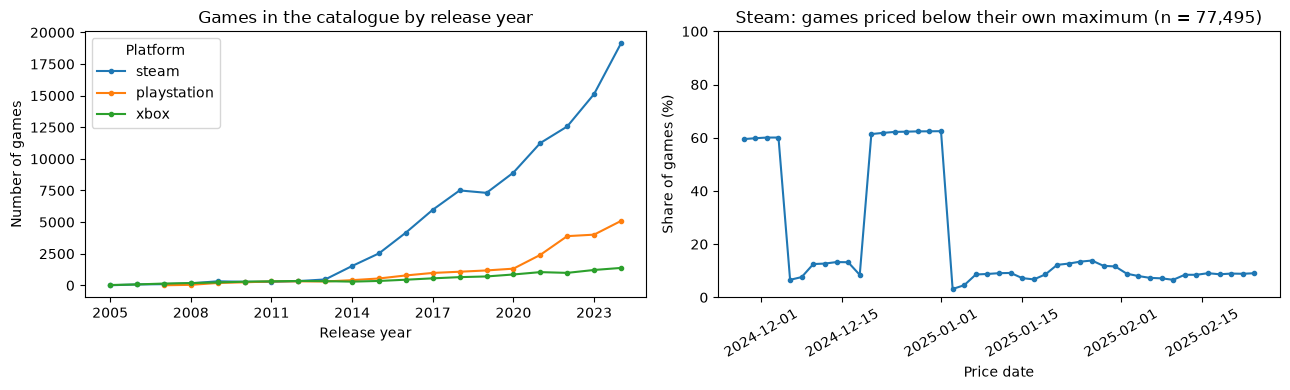

date_acquired
2024-11-28    59.5
2024-11-30    59.8
2024-12-02    60.1
2024-12-04    60.1
2024-12-20    61.4
2024-12-22    61.8
2024-12-24    62.2
2024-12-26    62.3
2024-12-28    62.4
2024-12-30    62.4
2025-01-01    62.5
Name: share_below_max_%, dtype: float64

In [15]:
# Steam is the only platform with a price time series: share of games below their own highest price on each date
steam_usd = game["steam", "prices"].pivot(index="gameid", columns="date_acquired", values="usd")
steam_usd = report_rows(steam_usd.dropna(), "Steam games with a USD price on every date", len(steam_usd))
below_max_pct = steam_usd.lt(steam_usd.max(axis=1), axis=0).mean() * 100

fig, (ax_release, ax_sale) = plt.subplots(1, 2, figsize=(13, 4))
for platform in PLATFORMS:
    per_year = game[platform, "games"]["release_date"].dt.year.value_counts().sort_index()
    ax_release.plot(per_year.loc[2005:2024], marker=".", label=platform)
ax_release.set(title="Games in the catalogue by release year", xlabel="Release year", ylabel="Number of games",
               xticks=range(2005, 2025, 3))
ax_release.legend(title="Platform")

ax_sale.plot(below_max_pct.index, below_max_pct.values, marker=".", color="tab:blue")
ax_sale.set(title=f"Steam: games priced below their own maximum (n = {len(steam_usd):,})",
            xlabel="Price date", ylabel="Share of games (%)", ylim=(0, 100))
ax_sale.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_release_years_and_steam_sales.png", dpi=150)
plt.show()
# Dates on which more than 30 % of games are below their own highest price: the sale windows
below_max_pct[below_max_pct > 30].round(1).rename("share_below_max_%")

#### Game side: observations

- **Release dates are plausible.** No date lies after the end of the collection, and at most 0.13 % fall on 1 January,
  so there is no sign of a default date. The catalogues are dominated by recent games: 68 % of Steam, 73 % of
  PlayStation and 53 % of Xbox games were released in 2020 or later. Steam alone added 19,128 games dated 2024, against
  2,528 dated 2015.
- **Price dates differ by platform.** Steam has 45 dates, one every two days, from 28 November 2024 to 24 February 2025.
  PlayStation has three dates, but 25 February holds only 1,374 rows against 30,721 on the other two days, so it is a
  partial snapshot. Xbox has two dates (22 and 24 February). **22 February 2025 is the only complete date shared by the
  three platforms**, and it is the reference day for price comparisons in sections 2.5 and 2.8.
- **Steam sales are visible in the data.** Among the 77,495 Steam games priced on every date, about 60 % sit below their
  own highest price from 28 November to 4 December and about 62 % from 20 December to 1 January, against 3 to 14 % on the
  other dates. These two windows match Steam's Autumn and Winter Sales 2024. The first one had already started when the
  collection began, so it has no "before" period in the data.

platform,steam,playstation,xbox
first,2008-09-13 01:37:54,2008-09-12 00:02:24,2008-09-12 00:01:45
last,2024-12-15 19:42:05,2024-12-29 04:54:45,2024-12-24 01:39:04
days_with_unlocks,5687,5953,5948
longest_gap_days,17,1,1
rows_on_12_13_Sep_2008,2,323,2277
busiest_day,2018-09-28,2023-01-06,2021-11-16
rows_on_busiest_day,190799,10589,8793
unlocks_in_same_second_groups_of_5+_%,55.3,1.5,1.3
pairs_started_in_last_90_days_%,2.3,1.3,0.9


,first,last,busiest_year,missing_%
posted,2010-10-15 00:00:00,2025-01-09 00:00:00,2024,0.0
created,2003-09-11 08:52:38,2025-01-07 19:57:59,2015,11.2


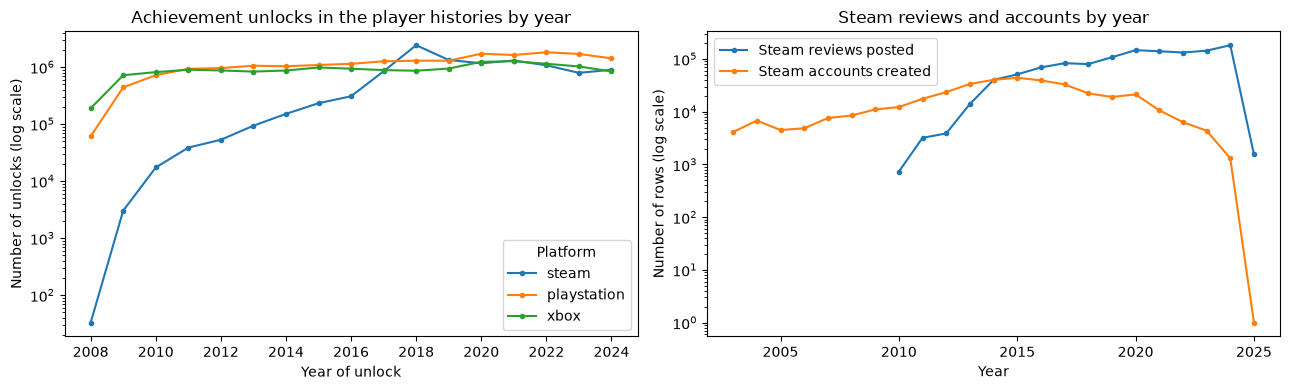

In [17]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
pairs = pd.read_parquet(PROCESSED_DIR / "history_player_game.parquet")  # written in section 2.3
PLACEHOLDER_DAYS = pd.to_datetime(["2008-09-12", "2008-09-13"])  # first date of all three platforms: a suspected default
history_end = pairs.groupby("platform")["last_unlock"].max()
started_in_last_90_days = (pairs["first_unlock"] > pairs["platform"].map(history_end) - pd.Timedelta(days=90)) \
    .groupby(pairs["platform"]).mean() * 100

history_rows, unlocks_per_year = [], {}
for platform in PLATFORMS:
    unlocks = load_player_table(platform, "history", usecols=["playerid", "date_acquired"])
    per_day = unlocks["date_acquired"].dt.normalize().value_counts().sort_index()
    # Several unlocks of one player in the same second cannot be played one by one: they come from a sync or a tool
    same_second = unlocks.groupby(["playerid", "date_acquired"])["date_acquired"].transform("size")
    history_rows.append({
        "platform": platform, "first": unlocks["date_acquired"].min(), "last": unlocks["date_acquired"].max(),
        "days_with_unlocks": len(per_day),
        "longest_gap_days": int(per_day.index.to_series().diff().dt.days.max()),
        "rows_on_12_13_Sep_2008": int(per_day.reindex(PLACEHOLDER_DAYS, fill_value=0).sum()),
        "busiest_day": per_day.idxmax().date(), "rows_on_busiest_day": int(per_day.max()),
        "unlocks_in_same_second_groups_of_5+_%": round(100 * (same_second >= 5).mean(), 1),
        "pairs_started_in_last_90_days_%": round(started_in_last_90_days[platform], 1),
    })
    unlocks_per_year[platform] = unlocks["date_acquired"].dt.year.value_counts().sort_index()
    del unlocks, same_second
    gc.collect()
display(pd.DataFrame(history_rows).set_index("platform").T)

reviews_posted = load_player_table("steam", "reviews", usecols=["posted"], parse_dates=["posted"])["posted"]
accounts_created = load_player_table("steam", "players", usecols=["created"], parse_dates=["created"])["created"]
date_columns = pd.DataFrame({
    column.name: {"first": column.min(), "last": column.max(), "busiest_year": int(column.dt.year.value_counts().idxmax()),
                  "missing_%": round(100 * column.isna().mean(), 1)}
    for column in [reviews_posted, accounts_created]
}).T
display(date_columns)

fig, (ax_history, ax_other) = plt.subplots(1, 2, figsize=(13, 4))
for platform, per_year in unlocks_per_year.items():
    ax_history.plot(per_year.index, per_year.values, marker=".", label=platform)
ax_history.set(title="Achievement unlocks in the player histories by year", xlabel="Year of unlock",
               ylabel="Number of unlocks (log scale)", yscale="log")
ax_history.legend(title="Platform")

ax_other.plot(reviews_posted.dt.year.value_counts().sort_index(), marker=".", label="Steam reviews posted")
ax_other.plot(accounts_created.dt.year.value_counts().sort_index(), marker=".", label="Steam accounts created")
ax_other.set(title="Steam reviews and accounts by year", xlabel="Year", ylabel="Number of rows (log scale)", yscale="log")
ax_other.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_player_time_coverage.png", dpi=150)
plt.show()

#### Player side: observations

- **Unlock histories run from 12 September 2008 to December 2024** (last unlock: 15 December on Steam, 29 on PlayStation,
  24 on Xbox). PlayStation and Xbox have unlocks every day; Steam has one gap of 17 days. 2008 is a partial year, so the
  series starts when tracking started. We cannot tell whether the 323 PlayStation and 2,277 Xbox rows dated 12 and 13
  September 2008 are real or defaults; they are negligible.
- **Steam shows a spike and many bulk unlocks.** 190,799 Steam unlocks (1.8 %) are dated 28 September 2018, against at
  most 10,589 on any day elsewhere. 55.3 % of the Steam unlocks sit in groups of five or more by the same player in the
  same second (1.5 % on PlayStation, 1.3 % on Xbox). This is not human speed: it points to synchronisation or
  unlocking tools, so Steam clock times are unreliable and time-based analyses need a robustness check without these rows.
- **The end of the data matters little.** Only 2.3 % (Steam), 1.3 % (PlayStation) and 0.9 % (Xbox) of the pairs start in
  the last 90 days, so a 90-day observation window removes few rows (see section 2.8).
- **Reviews and accounts.** Reviews run from 15 October 2010 to 9 January 2025 (2025 is partial, 1,552 reviews). Steam
  accounts were created between 11 September 2003 and 7 January 2025 (11.2 % undated); creations peak in 2015, which
  reflects how players were sampled (section 1.4) rather than Steam itself.

### 2.5 Numerical columns

Distribution, centre and spread, plausible minimum and maximum, and outliers (IQR rule, z-score) for the columns the
candidate questions use: review votes and length, unlocks per (player, game) pair, library and friend-list sizes.

In [17]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
COMMON_DAY = pd.Timestamp("2025-02-22")  # the only date with prices for all three platforms; Steam is not on sale

usd_rows, zero_rows = [], []
for platform in PLATFORMS:
    prices = game[platform, "prices"]
    usd = prices.loc[prices["date_acquired"] == COMMON_DAY, "usd"].dropna()
    q1, q3 = usd.quantile([0.25, 0.75])
    usd_rows.append({
        "platform": platform, "games_priced": len(usd), "median": usd.median(), "mean": round(usd.mean(), 2),
        "Q1": q1, "Q3": q3, "max": usd.max(), "skewness": round(usd.skew(), 1),
        "above_Q3_plus_1.5_IQR_%": round(100 * (usd > q3 + 1.5 * (q3 - q1)).mean(), 1),
    })
    # a 0 in one currency while the same row has a positive USD price is a placeholder, not a free game
    zero_rows.append({"platform": platform, "zero_usd": int((prices["usd"] == 0).sum()),
                      **{f"zero_{c}_with_positive_usd": int(((prices[c] == 0) & (prices["usd"] > 0)).sum())
                         for c in ["eur", "gbp", "jpy", "rub"]}})
display(pd.DataFrame(usd_rows))
display(pd.DataFrame(zero_rows).set_index("platform"))

# The most expensive Steam prices: real products or errors?
steam_titles = game["steam", "games"].set_index("gameid")["title"]
top = (game["steam", "prices"].groupby("gameid")["usd"].max().nlargest(5).to_frame("max_usd")
       .join(steam_titles))
top

,platform,games_priced,median,mean,Q1,Q3,max,skewness,above_Q3_plus_1.5_IQR_%
0,steam,77985,4.99,9.09,2.99,9.99,999.98,16.8,5.9
1,playstation,24049,7.99,12.11,2.99,17.99,99.99,1.8,2.8
2,xbox,8001,14.99,17.15,7.99,19.99,109.99,1.6,8.7


,zero_usd,zero_eur_with_positive_usd,zero_gbp_with_positive_usd,zero_jpy_with_positive_usd,zero_rub_with_positive_usd
platform,,,,,
steam,0,0,45,0,25
playstation,0,0,0,0,2
xbox,0,0,0,0,0


,max_usd,title
gameid,,
2499620,999.98,The Leverage Game
2504210,999.98,The Leverage Game Business Edition
1200520,999.00,Ascent Free-Roaming VR Experience
3013840,500.00,True Love
1105450,299.99,Aartform Curvy 3D 4.0


,platform,games,median,p90,p99,max,game_with_max
0,steam,50548,18.0,54.0,152.0,10979,The Mexican Dream
1,playstation,30721,22.0,51.0,71.0,411,Train Sim World 2
2,xbox,11319,26.0,52.0,100.0,700,Halo: The Master Chief Collection


Xbox points per achievement: median 20, 796 achievements worth 0, max 1000
Xbox points per game (gamerscore): median 1000, 76% of games total exactly 1,000


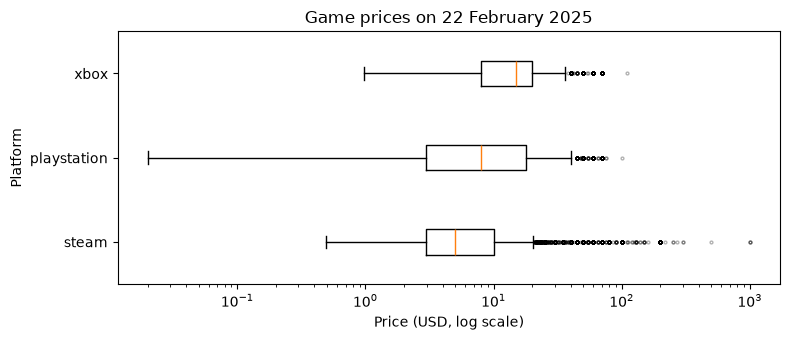

In [18]:
# Achievements per game and Xbox points
ach_rows = []
for platform in PLATFORMS:
    per_game = game[platform, "achievements"].groupby("gameid").size()
    ach_rows.append({"platform": platform, "games": len(per_game), "median": per_game.median(),
                     "p90": per_game.quantile(0.9), "p99": per_game.quantile(0.99), "max": per_game.max(),
                     "game_with_max": game[platform, "games"].set_index("gameid")["title"].get(per_game.idxmax())})
display(pd.DataFrame(ach_rows))

xbox_points = game["xbox", "achievements"]
points_per_game = xbox_points.groupby("gameid")["points"].sum()
print(f"Xbox points per achievement: median {xbox_points['points'].median():.0f}, "
      f"{(xbox_points['points'] == 0).sum():,} achievements worth 0, max {xbox_points['points'].max()}")
print(f"Xbox points per game (gamerscore): median {points_per_game.median():.0f}, "
      f"{(points_per_game == 1000).mean():.0%} of games total exactly 1,000")

# Price distribution on the common day (log scale: prices are strongly right-skewed)
fig, ax = plt.subplots(figsize=(8, 3.5))
data = [game[p, "prices"].loc[lambda d: d["date_acquired"] == COMMON_DAY, "usd"].dropna() for p in PLATFORMS]
ax.boxplot(data, orientation="horizontal", showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
ax.set_yticks(range(1, len(PLATFORMS) + 1), PLATFORMS)
ax.set_xscale("log")
ax.set(title="Game prices on 22 February 2025", xlabel="Price (USD, log scale)", ylabel="Platform")
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_price_distribution.png", dpi=150)
plt.show()

#### Game side: observations

- **Prices are strongly right-skewed.** On 22 February 2025 the median price is USD 4.99 on Steam (IQR 2.99 to 9.99,
  mean 9.09, skewness 16.8), USD 7.99 on PlayStation and USD 14.99 on Xbox. The IQR rule flags 5.9 % of Steam prices
  and 8.7 % of Xbox prices as outliers, but its thresholds (about USD 20 on Steam and USD 38 on Xbox) fall on ordinary
  full-price games, so the rule is not used to remove rows; prices are analysed on a log scale or by their median.
- **Extreme values are mostly genuine.** The highest Steam prices (USD 999.98 for *The Leverage Game*, USD 999 for a VR
  experience) are real store prices of niche products and are kept. One PlayStation game costs USD 0.02 but EUR 0.26,
  which looks like an error; such cases are rare and are checked again in the analyses that use prices.
- **Zero prices are placeholders.** 45 GBP and 25 RUB prices on Steam and 2 RUB prices on PlayStation are exactly 0 while
  the same row has a positive USD price, so a 0 is treated as missing.
- **Achievements per game** have a median of 18 (Steam), 22 (PlayStation) and 26 (Xbox). Steam has extreme
  "achievement spam" games, up to 10,979 achievements for *The Mexican Dream*; the 99th percentile is 152.
- **Xbox points follow a platform rule:** 76 % of Xbox games total exactly 1,000 gamerscore points, and a single
  achievement is worth 20 points at the median.

In [20]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
# Reviews: read the text once, keep only small features, and write them to data/processed/ for sections 2.6 and 2.8
reviews = load_player_table("steam", "reviews")
text = reviews.pop("review")
reviews["text_missing"] = text.isna()
reviews["n_words"] = text.str.split().str.len().astype("Int32")  # missing text gives <NA>
reviews["is_ascii"] = text.map(lambda t: t.isascii() if isinstance(t, str) else pd.NA).astype("boolean")  # False: emoji, accents, other scripts
del text
gc.collect()
reviews.to_parquet(PROCESSED_DIR / "steam_review_features.parquet", index=False)

votes = ["helpful", "funny", "awards", "n_words"]
numeric_rows = []
for column in votes:
    values = reviews[column].dropna().astype("float64")
    q1, q3 = values.quantile([0.25, 0.75])
    numeric_rows.append({
        "column": column, "median": values.median(), "mean": round(values.mean(), 2), "p99": values.quantile(0.99),
        "max": values.max(), "zero_%": round(100 * (values == 0).mean(), 1), "skewness": round(values.skew(), 1),
        "IQR_rule_outliers_%": round(100 * (values > q3 + 1.5 * (q3 - q1)).mean(), 1),
        "z_score_above_3_%": round(100 * ((values - values.mean()) / values.std() > 3).mean(), 2),
    })
display(pd.DataFrame(numeric_rows).set_index("column"))

# Values that look like parsing artefacts (section 1.4): no review has exactly 1 helpful vote; votes are cut at 999
print("reviews with helpful == 1:", int((reviews["helpful"] == 1).sum()), "| helpful == 2:", int((reviews["helpful"] == 2).sum()),
      "| helpful == 999:", int((reviews["helpful"] == 999).sum()), "| funny == 999:", int((reviews["funny"] == 999).sum()))
# The most awarded reviews: genuine, or a pattern (same author, same day)?
reviews.nlargest(5, "awards")[["reviewid", "playerid", "gameid", "posted", "helpful", "awards", "n_words"]]

,median,mean,p99,max,zero_%,skewness,IQR_rule_outliers_%,z_score_above_3_%
column,,,,,,,,
helpful,0.0,5.58,91.0,999.0,66.0,16.0,12.9,1.00
funny,0.0,1.25,20.0,988.0,89.8,34.3,10.2,0.44
awards,0.0,0.52,9.0,8851.0,93.0,342.9,7.0,0.12
n_words,9.0,51.42,689.0,4000.0,0.0,5.4,13.3,2.21


reviews with helpful == 1: 0 | helpful == 2: 98268 | helpful == 999: 1 | funny == 999: 0


,reviewid,playerid,gameid,posted,helpful,awards,n_words
337958,977533,76561199014028512,730,2022-10-05,3,8851,7
337959,977534,76561199014028512,465190,2022-10-05,0,8748,17
337960,977535,76561199014028512,375320,2022-10-05,0,8440,40
337978,977553,76561199014028512,595090,2022-06-05,3,5232,13
337797,977554,76561199014028512,501220,2022-06-05,3,5054,24


platform,steam,playstation,xbox
pairs,276036.00,995079.0,1010783.0
unlocks_median,9.00,14.0,10.0
unlocks_p99,352.65,72.0,74.0
unlocks_max,10979.00,264.0,700.0
single_unlock_%,12.40,9.5,13.5
active_days_median,4.00,6.0,4.0
active_days_p99,2765.00,2098.0,2488.0
same_day_%,40.50,35.1,39.3
unlocks_above_game_size,0.00,0.0,0.0


,non_empty_rows,median,p99,max,exactly_1_%,rows_at_the_maximum
table,,,,,,
steam purchased_games,46941,76.0,3137.60,32463.0,1.2,1
playstation purchased_games,46582,157.0,1345.38,13540.0,0.1,1
xbox purchased_games,46466,172.0,1908.05,9018.0,0.2,1
steam friends,339461,62.0,427.00,2000.0,1.5,16


Steam account age (years, at 10 January 2025): median 9.7, min 0.01, max 21.3, missing 11.2%


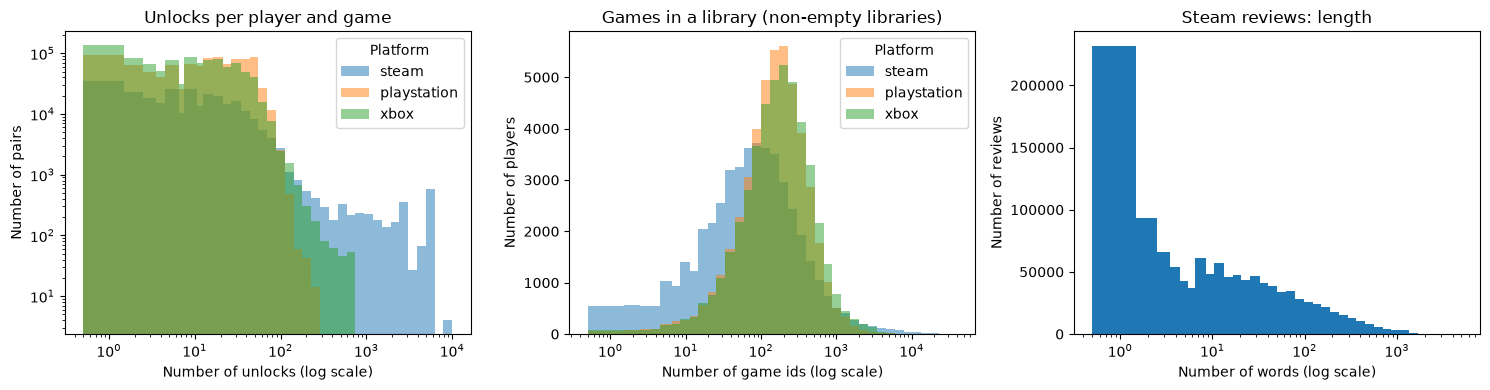

In [21]:
# Unlocks per (player, game) pair, days between first and last unlock, and a logical check against the game's size
pairs = pd.read_parquet(PROCESSED_DIR / "history_player_game.parquet")  # written in section 2.3
pairs["active_days"] = (pairs["last_unlock"] - pairs["first_unlock"]).dt.days
achievements_in_game = pd.concat({p: game[p, "achievements"].groupby("gameid").size() for p in PLATFORMS},
                                 names=["platform", "gameid"]).rename("n_achievements")
pairs = pairs.join(achievements_in_game, on=["platform", "gameid"])

pair_rows = []
for platform, group in pairs.groupby("platform", sort=False):
    pair_rows.append({
        "platform": platform, "pairs": len(group),
        "unlocks_median": group["n_unlocks"].median(), "unlocks_p99": group["n_unlocks"].quantile(0.99),
        "unlocks_max": group["n_unlocks"].max(), "single_unlock_%": round(100 * (group["n_unlocks"] == 1).mean(), 1),
        "active_days_median": group["active_days"].median(), "active_days_p99": group["active_days"].quantile(0.99),
        "same_day_%": round(100 * (group["active_days"] == 0).mean(), 1),
        # impossible: more unlocks than the game has achievements
        "unlocks_above_game_size": int((group["n_unlocks"] > group["n_achievements"]).sum()),
    })
display(pd.DataFrame(pair_rows).set_index("platform").T)

# Library and friend list sizes: the lists are stored as text, so count the items
size_rows, sizes = [], {}
for platform, table, column in [("steam", "purchased_games", "library"), ("playstation", "purchased_games", "library"),
                                ("xbox", "purchased_games", "library"), ("steam", "friends", "friends")]:
    items = count_list_items(load_player_table(platform, table)[column]).astype("float64")
    items = items[items > 0]  # empty cells are missing data (section 2.1), not a list of length 0
    sizes[platform, table] = items
    size_rows.append({"table": f"{platform} {table}", "non_empty_rows": len(items), "median": items.median(),
                      "p99": items.quantile(0.99), "max": items.max(), "exactly_1_%": round(100 * (items == 1).mean(), 1),
                      "rows_at_the_maximum": int((items == items.max()).sum())})
display(pd.DataFrame(size_rows).set_index("table"))

account_age = (pd.Timestamp("2025-01-10") - load_player_table("steam", "players", usecols=["created"], parse_dates=["created"])["created"]).dt.days / 365.25
print(f"Steam account age (years, at 10 January 2025): median {account_age.median():.1f}, "
      f"min {account_age.min():.2f}, max {account_age.max():.1f}, missing {account_age.isna().mean():.1%}")

def integer_log_bins(upper_exponent, n=40):
    """Log-spaced bin edges that never fall between two consecutive integers (counts are whole numbers)."""
    return np.unique(np.round(np.logspace(0, upper_exponent, n))) - 0.5

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for platform in PLATFORMS:
    axes[0].hist(pairs.loc[pairs["platform"] == platform, "n_unlocks"], bins=integer_log_bins(4), alpha=0.5, label=platform)
axes[0].set(title="Unlocks per player and game", xlabel="Number of unlocks (log scale)", ylabel="Number of pairs", xscale="log", yscale="log")
axes[0].legend(title="Platform")
for (platform, table), items in sizes.items():
    if table == "purchased_games":
        axes[1].hist(items, bins=integer_log_bins(4.6), alpha=0.5, label=platform)
axes[1].set(title="Games in a library (non-empty libraries)", xlabel="Number of game ids (log scale)", ylabel="Number of players", xscale="log")
axes[1].legend(title="Platform")
axes[2].hist(reviews["n_words"].dropna().clip(lower=1), bins=integer_log_bins(3.7), color="tab:blue")
axes[2].set(title="Steam reviews: length", xlabel="Number of words (log scale)", ylabel="Number of reviews", xscale="log")
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_player_distributions.png", dpi=150)
plt.show()

#### Player side: observations

**Reviews** (1,204,534 rows)

- **Votes are very right-skewed.** 66.0 % of the reviews have no helpful vote (median 0, mean 5.58, 99th percentile 91,
  skewness 16.0); 89.8 % have no funny vote and 93.0 % no award. Reviews have a median of 9 words but a mean of 51.4
  (skewness 5.4). The IQR rule flags 7 to 13 % of the values and the z-score rule 0.1 to 2.2 %, too many to be errors,
  so no review is removed; we use log scales, medians and rank correlations.
- **Placeholder and cut values (section 1.4).** No review has exactly one helpful vote while 98,268 have two, so
  `helpful > 0` means at least two votes. Votes of 1,000 or more keep only their last three digits, so the maximum of 999
  and the upper tail of `helpful` and `funny` are unreliable.
- **Awards are real but concentrated.** The five most awarded reviews (up to 8,851) share one author, 19 reviews exceed
  1,000 awards (nine authors) and the ten most awarded hold 7.9 % of all awards, so averages over `awards` are driven by
  a few accounts.

**History, libraries and friends**

- **Unlocks per (player, game) pair:** median 9 (Steam), 14 (PlayStation), 10 (Xbox); 12.4 %, 9.5 % and 13.5 % of the
  pairs have a single unlock and about 40 % of the Steam and Xbox pairs span one day or less. The Steam tail is long
  (99th percentile 353, maximum 10,979 = the game with the most achievements), the console tails short (maxima 264 and
  700). No pair exceeds the game's number of achievements, so the pair table is consistent.
- **Libraries** (non-empty): median 76 (Steam), 157 (PlayStation), 172 (Xbox); the maxima (32,463, 13,540, 9,018) are single
  players, probably collectors or lists of games merely seen. **Friend lists:** median 62, maximum exactly 2,000 for 16
  players, which looks like a cap.
- **Steam account age** at 10 January 2025: median 9.7 years (0.01 to 21.3; 11.2 % missing).

### 2.6 Categorical columns

Distinct values, balance, inconsistent labels and rare categories for `country`, and the binary-like columns of
`reviews` (votes, awards, language, length, concentration on games and authors).

,platform,labels,labels_ignoring_case,inconsistent_examples,labels_per_game_median,rare_labels_under_1%,top_5
0,steam,33,33,[],3.0,21,"[(Indie, 70.1), (Casual, 43.0), (Action, 41.3)..."
1,playstation,120,115,"[[Fighting, fighting], [Platformer, platformer...",1.0,87,"[(Action, 13.9), (Platformer, 11.5), (Puzzle, ..."
2,xbox,113,108,"[[Fighting, fighting], [Platformer, platformer...",1.0,73,"[(Adventure, 20.1), (Action, 15.9), (Platforme..."


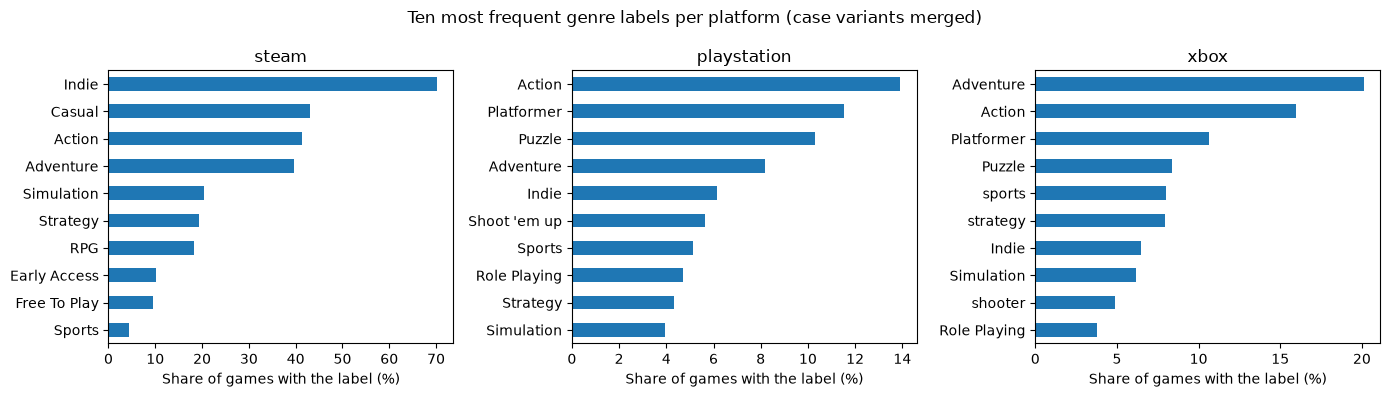

In [20]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
genre_rows, genre_shares = [], {}
for platform in PLATFORMS:
    games = game[platform, "games"]
    labels = parse_list_column(games["genres"]).explode().dropna().str.strip()  # index = row of the game
    lower = labels.str.lower()
    spellings = labels.groupby(lower).unique()                     # spellings of each label, ignoring case
    inconsistent = spellings[spellings.map(len) > 1]
    canonical = lower.map(labels.groupby(lower).agg(lambda s: s.mode()[0]))  # most frequent spelling
    per_game = canonical.rename("label").reset_index().drop_duplicates()     # each label once per game
    share = per_game["label"].value_counts() / games["genres"].notna().sum() * 100  # % of games with the label
    genre_shares[platform] = share
    genre_rows.append({
        "platform": platform, "labels": labels.nunique(), "labels_ignoring_case": len(spellings),
        "inconsistent_examples": [list(v) for v in inconsistent.head(3)],
        "labels_per_game_median": parse_list_column(games["genres"]).str.len().median(),
        "rare_labels_under_1%": int((share < 1).sum()),
        "top_5": list(share.head(5).round(1).items()),
    })
display(pd.DataFrame(genre_rows))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, platform in zip(axes, PLATFORMS):
    genre_shares[platform].head(10).sort_values().plot.barh(ax=ax)
    ax.set(title=platform, xlabel="Share of games with the label (%)", ylabel="")
fig.suptitle("Ten most frequent genre labels per platform (case variants merged)")
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_top_genres.png", dpi=150)
plt.show()

In [21]:
# Other categorical columns: PlayStation console and trophy grade, publishers, languages
ps_trophies = game["playstation", "achievements"]
platinum_per_game = ps_trophies.assign(is_platinum=ps_trophies["rarity"] == "Platinum").groupby("gameid")["is_platinum"].sum()
display(pd.concat({
    "PS games by console (%)": game["playstation", "games"]["platform"].value_counts(normalize=True).mul(100).round(1),
    "PS trophies by grade (%)": ps_trophies["rarity"].value_counts(normalize=True, sort=False).mul(100).round(1),
}))
print("PS games by number of Platinum trophies:", platinum_per_game.value_counts().sort_index().to_dict())

other_rows = []
for platform in PLATFORMS:
    games = game[platform, "games"]
    publishers = parse_list_column(games["publishers"]).explode().dropna()
    other_rows.append({
        "platform": platform,
        "distinct_publishers": publishers.nunique(),
        "top_3_publishers": list(publishers.value_counts().head(3).items()),
        "languages_per_game_median": parse_list_column(games["supported_languages"]).str.len().median(),
    })
pd.DataFrame(other_rows)

PS games by console (%)   PS4         61.2
                          PS5         27.7
                          PS3          6.8
                          PS Vita      4.3
PS trophies by grade (%)  Bronze      51.7
                          Silver      24.9
                          Gold        20.4
                          Platinum     3.0
Name: proportion, dtype: float64

PS games by number of Platinum trophies: {0: 5132, 1: 25589}


,platform,distinct_publishers,top_3_publishers,languages_per_game_median
0,steam,50803,"[(Big Fish Games, 511), (8floor, 268), (SEGA, ...",1.0
1,playstation,2538,"[(eastasiasoft, 1185), (Ratalaika Games, 966),...",6.0
2,xbox,2268,"[(Microsoft Studios, 386), (Electronic Arts, 2...",5.0


#### Game side: observations

- **Genre labels are not comparable across platforms.** Steam uses 33 clean store labels, a median of 3 per game, and
  some are not genres at all (*Indie* on 70 % of games, *Early Access*, *Free To Play*). PlayStation (120 labels) and Xbox
  (113) use a finer taxonomy with typically one label per game, and the same label appears in different cases
  (*Puzzle* and *puzzle*, *Fighting* and *fighting*), leaving 115 and 108 labels once case is ignored. 87 PlayStation and
  73 Xbox labels cover less than 1 % of games each.
- **Decision:** merge case variants (keep the most frequent spelling), group labels under 1 % as "Other", and compare
  genres within a platform rather than across platforms.
- **PlayStation:** 61 % of games are PS4 and 28 % PS5 versions. Trophies are 52 % Bronze, 25 % Silver, 20 % Gold and 3 %
  Platinum. No game has more than one Platinum: 25,589 games have one and 5,132 have none.
- **Publishers** form a long tail: Steam has 50,803 distinct publishers, the largest (Big Fish Games) with only 511 games.
  On PlayStation the most frequent publishers are budget porting labels (eastasiasoft 1,185 games, Ratalaika Games 966).

platform,steam,playstation
players_with_country,246815,356600
distinct_countries,249,70
distinct_after_strip_and_lower,249,70
top_country,United States (12.1%),United States (22.8%)
top_5_share_%,40.4,56.1
countries_under_1%,228,50
share_of_these_%,25.9,10.3


countries only on Steam: 179, only on PlayStation: 0; examples only on PlayStation: []


,value
helpful > 0 (%),34.0
funny > 0 (%),10.2
awards > 0 (%),7.0
text missing (%),0.2
text with non-ASCII characters (%),41.6
reviews of 3 words or fewer (%),32.5
distinct games reviewed,51910.0
reviews of the 10 most reviewed games (%),13.2
distinct authors,196698.0
authors with a single review (%),40.3


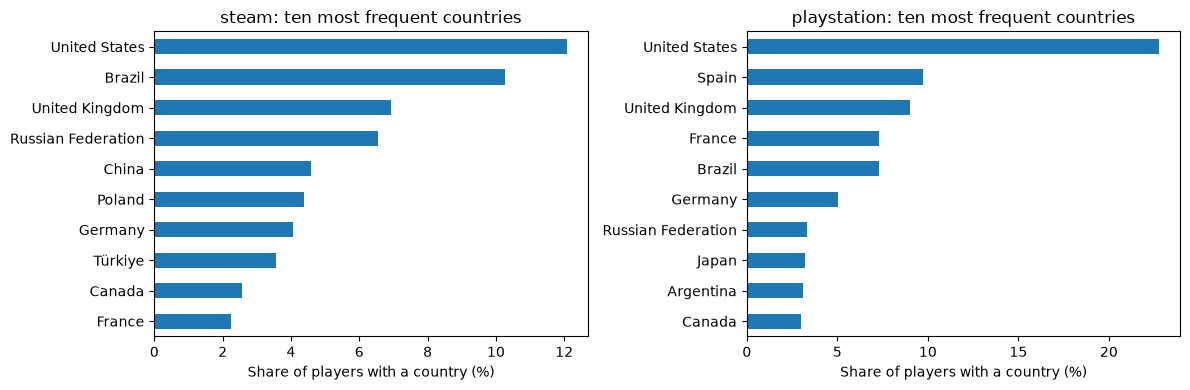

In [24]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
country_rows, country_share = [], {}
for platform in ["steam", "playstation"]:  # Xbox profiles have no country
    country = load_player_table(platform, "players", usecols=["country"], parse_dates=[])["country"].astype("object").dropna()
    share = country.value_counts(normalize=True) * 100
    country_share[platform] = share
    cleaned = country.str.strip().str.lower()
    country_rows.append({
        "platform": platform, "players_with_country": len(country), "distinct_countries": country.nunique(),
        "distinct_after_strip_and_lower": cleaned.nunique(),
        "top_country": f"{share.index[0]} ({share.iloc[0]:.1f}%)", "top_5_share_%": round(share.head(5).sum(), 1),
        "countries_under_1%": int((share < 1).sum()), "share_of_these_%": round(share[share < 1].sum(), 1),
    })
display(pd.DataFrame(country_rows).set_index("platform").T)
only_steam, only_ps = set(country_share["steam"].index) - set(country_share["playstation"].index), \
    set(country_share["playstation"].index) - set(country_share["steam"].index)
print(f"countries only on Steam: {len(only_steam)}, only on PlayStation: {len(only_ps)}; "
      f"examples only on PlayStation: {sorted(only_ps)[:6]}")

# Reviews: the categorical-like columns (read from the features written in section 2.5)
review_features = pd.read_parquet(PROCESSED_DIR / "steam_review_features.parquet")
per_game = review_features["gameid"].value_counts()
per_author = review_features["playerid"].value_counts()
display(pd.Series({
    "helpful > 0 (%)": 100 * (review_features["helpful"] > 0).mean(),
    "funny > 0 (%)": 100 * (review_features["funny"] > 0).mean(),
    "awards > 0 (%)": 100 * (review_features["awards"] > 0).mean(),
    "text missing (%)": 100 * review_features["text_missing"].mean(),
    "text with non-ASCII characters (%)": 100 * (~review_features["is_ascii"].dropna().astype(bool)).mean(),
    "reviews of 3 words or fewer (%)": 100 * (review_features["n_words"] <= 3).mean(),
    "distinct games reviewed": per_game.size,
    "reviews of the 10 most reviewed games (%)": 100 * per_game.head(10).sum() / len(review_features),
    "distinct authors": per_author.size,
    "authors with a single review (%)": 100 * (per_author == 1).mean(),
    "most reviews by one author": per_author.iloc[0],
}).round(1).rename("value").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, platform in zip(axes, ["steam", "playstation"]):
    country_share[platform].head(10).sort_values().plot.barh(ax=ax)
    ax.set(title=f"{platform}: ten most frequent countries", xlabel="Share of players with a country (%)", ylabel="")
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_player_countries.png", dpi=150)
plt.show()

#### Player side: observations

- **`country` is clean but unbalanced.** 249 countries on Steam, 70 on PlayStation, none on Xbox; no case or whitespace
  variants, and every PlayStation country appears on Steam with the same name. The United States leads (12.1 % of Steam and
  22.8 % of PlayStation players with a country); the top five hold 40.4 % and 56.1 %. A long tail remains: 228 Steam
  countries (25.9 % of players) and 50 PlayStation countries (10.3 %) have less than 1 % each.
- **Decision:** keep countries with at least 1 % of the players, group the rest as "Other" and the 41.9 % of Steam players
  without a country as "Unknown" (section 2.7).
- **Review votes are imbalanced.** 34.0 % of the reviews have at least two helpful votes, 10.2 % a funny vote and 7.0 % an
  award, so always predicting "no votes" is right 66 % of the time and accuracy would mislead.
- **Review text.** 41.6 % of the texts contain non-ASCII characters, 32.5 % have three words or fewer and 0.2 % are
  missing; many are placeholders (section 2.2), so language and length features need care.
- **Concentration.** The reviews cover 51,910 games; the ten most reviewed hold 13.2 %. They come from 196,698 authors, 40.3 %
  of whom wrote one review, and one author wrote 14,893, so train and test splits should take authors and games into
  account.

### 2.7 Missing data

Count and share of missing values per column, whether the gaps come together (Steam), and how each column is handled.

In [23]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
# Share of missing values per column (%), one column per platform; only columns with missing values
missing = pd.concat(
    {(name, platform): game[platform, name].isna().mean() * 100 for platform, name in GAME_SIDE_TABLES},
    names=["table", "platform", "column"],
).unstack("platform")[PLATFORMS]
display(missing[missing.sum(axis=1) > 0].round(1))

# Patterns behind the gaps
steam_games = game["steam", "games"]
no_metadata = steam_games["genres"].isna()
is_playtest = steam_games["title"].str.contains("playtest", case=False, na=False)
print(f"Steam games without genres: {no_metadata.sum():,}; "
      f"of these {(no_metadata & steam_games['developers'].isna()).mean() / no_metadata.mean():.0%} also lack developers "
      f"and {(no_metadata & is_playtest).sum() / no_metadata.sum():.0%} are playtests")

price_gaps = []
for platform in PLATFORMS:
    prices = game[platform, "prices"]
    never_usd = prices.groupby("gameid")["usd"].count() == 0
    price_gaps.append({
        "platform": platform,
        "games_never_priced_in_usd": int(never_usd.sum()),
        "games_never_priced_%": round(100 * never_usd.mean(), 1),
        "rows_with_usd_but_no_eur_%": round(100 * (prices["usd"].notna() & prices["eur"].isna()).mean(), 1),
    })
pd.DataFrame(price_gaps)

platform                          steam  playstation   xbox
table        column                                        
achievements description            8.9          0.0    0.0
             points                 NaN          NaN    0.3
             title                  0.2          0.0    0.0
games        developers             5.7          0.1    5.5
             genres                 5.6          0.6    5.8
             publishers             6.0          0.0    5.2
             supported_languages    5.6         54.2   63.4
             title                  0.0          0.0    0.0
prices       eur                   38.6         24.8   32.6
             gbp                   20.6         22.6   30.2
             jpy                   20.8         57.0  100.0
             rub                   22.8         82.6   36.5
             usd                   20.6         21.6   29.3

Steam games without genres: 5,549; of these 98% also lack developers and 95% are playtests


,platform,games_never_priced_in_usd,games_never_priced_%,rows_with_usd_but_no_eur_%
0,steam,20049,20.4,18.0
1,playstation,6664,21.7,4.7
2,xbox,3317,29.3,3.5


#### Game side: observations

- **Game metadata is missing together.** The 5,549 Steam games without genres almost always lack developers as well
  (98 %), and 95 % of them are playtests, which have no store page. The gap is therefore not random and concerns test
  builds rather than real games.
- **Missing USD prices mean "not for sale"**: 20,049 Steam games (20.4 %), 6,664 PlayStation games and 3,317 Xbox games
  never have a USD price in any snapshot (free games or games not sold in the US store).
- **Other currencies are less complete.** 18 % of Steam rows have a USD price but no EUR price; Xbox has no JPY price at
  all, and 83 % of PlayStation RUB prices are missing.
- `supported_languages` is missing for 54 % of PlayStation and 63 % of Xbox games; `achievements.description` is missing
  for 8.9 % of Steam achievements.

| Column | Missing | Handling |
| --- | --- | --- |
| `games.genres`, `developers`, `publishers` | 5 to 6 % (Steam, Xbox) | keep the rows; "Unknown" when a genre is needed; playtests excluded from game-level analyses |
| `games.supported_languages` | 54 to 63 % on consoles | descriptive use only, never as a model feature on consoles |
| `prices.usd` | 21 to 29 % of rows | drop the row in price analyses (the game is not for sale) |
| `prices.eur`, `gbp`, `jpy`, `rub` | 21 to 100 % | not used in the questions; summaries only |
| `achievements.points` (Xbox) | 0.3 % | keep; ignored in sums |
| `achievements.description` | 8.9 % (Steam) | not used |

In [26]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
review_features = pd.read_parquet(PROCESSED_DIR / "steam_review_features.parquet")  # written in section 2.5
pairs = pd.read_parquet(PROCESSED_DIR / "history_player_game.parquet")                # written in section 2.3

# Share of missing values per column (%). history is read one column at a time: only the date can be missing
missing_rows = []
def add_missing(platform, table, column, n_missing, n_rows):
    missing_rows.append({"table": table, "column": column, "platform": platform, "missing": int(n_missing),
                         "missing_%": round(100 * n_missing / n_rows, 1)})
for platform, table in PLAYER_SIDE_TABLES:
    if table in ("players", "purchased_games", "friends"):
        df = load_player_table(platform, table)
        for column in df.columns.drop("playerid"):
            add_missing(platform, table, column, df[column].isna().sum(), len(df))
    elif table == "history":
        dates = load_player_table(platform, table, usecols=["date_acquired"])["date_acquired"]
        add_missing(platform, table, "date_acquired", dates.isna().sum(), len(dates))
        del dates
        gc.collect()
add_missing("steam", "reviews", "review (text)", review_features["text_missing"].sum(), len(review_features))
display(pd.DataFrame(missing_rows).set_index(["table", "column", "platform"]))

# Steam: do the gaps come together? Hypothesis: private or incomplete profiles lack country, library and friends
steam = load_player_table("steam", "players")
steam["country_missing"] = steam["country"].isna()
steam["created_missing"] = steam["created"].isna()
steam["friends_empty"] = steam["playerid"].map(load_player_table("steam", "friends").set_index("playerid")["friends"].isna())
library = load_player_table("steam", "purchased_games").set_index("playerid")["library"]
steam["library_listed"] = steam["playerid"].isin(library.index)                  # has a row in purchased_games
steam["library_non_empty"] = steam["playerid"].isin(library.index[library.notna()])  # and the library is not an empty cell
steam["is_reviewer"] = steam["playerid"].isin(review_features["playerid"])
steam["has_history"] = steam["playerid"].isin(pairs.loc[pairs["platform"] == "steam", "playerid"])

def profile_of_group(by):
    return steam.groupby(by).agg(players=("playerid", "size"),
                                 created_missing_pct=("created_missing", "mean"), friends_empty_pct=("friends_empty", "mean"),
                                 library_non_empty_pct=("library_non_empty", "mean"), reviewers_pct=("is_reviewer", "mean"),
                                 with_history_pct=("has_history", "mean")).round(3).assign(
        **{c: lambda d, c=c: (100 * d[c]).round(1) for c in ["created_missing_pct", "friends_empty_pct", "library_non_empty_pct", "reviewers_pct", "with_history_pct"]})
display(profile_of_group("country_missing"))
display(profile_of_group("created_missing"))
print(f"Steam players in purchased_games: {steam['library_listed'].sum():,} of {len(steam):,}; "
      f"with a non-empty library: {steam['library_non_empty'].sum():,}")

missing  missing_%
table           column        platform                       
players         country       steam         177868       41.9
                created       steam          47669       11.2
                nickname      playstation        0        0.0
                country       playstation        0        0.0
                nickname      xbox               0        0.0
history         date_acquired steam              0        0.0
                              playstation        0        0.0
                              xbox               0        0.0
purchased_games library       steam          55607       54.2
                              playstation        0        0.0
                              xbox               0        0.0
friends         friends       steam          85222       20.1
reviews         review (text) steam           2097        0.2

,players,created_missing_pct,friends_empty_pct,library_non_empty_pct,reviewers_pct,with_history_pct
country_missing,,,,,,
False,246815,0.0,10.4,13.4,53.1,1.4
True,177868,26.8,33.5,7.9,36.8,0.8


,players,created_missing_pct,friends_empty_pct,library_non_empty_pct,reviewers_pct,with_history_pct
created_missing,,,,,,
False,377014,0.0,10.3,12.4,46.8,1.3
True,47669,100.0,97.6,0.4,42.3,0.1


Steam players in purchased_games: 102,548 of 424,683; with a non-empty library: 46,941


#### Player side: observations

- **Missing values are concentrated in the Steam tables:** 41.9 % of players have no `country`, 11.2 % no creation date,
  54.2 % of the libraries and 20.1 % of the friend lists are empty, and 0.2 % of the reviews have no text. PlayStation,
  Xbox and all `history` dates are complete.
- **The gaps come together.** The 47,669 Steam accounts without a creation date also lack a country; 97.6 % have an empty
  friend list, 0.4 % a non-empty library and 0.1 % have unlocks (against 10.3 %, 12.4 % and 1.3 % for dated accounts).
  Players without a country are a broader group (41.9 %): 26.8 % also lack the date, 33.5 % have an empty friend list
  (10.4 % with a country) and 7.9 % a library (13.4 %).
- **Likely cause: private or hidden profiles, not proven.** 42.3 % of the undated accounts still have reviews, which stay
  visible on private profiles. Only 46,941 of 424,683 Steam players (11.1 %) have a non-empty library, so library
  analyses describe a small open-profile group (section 1.4, limitation 3). The gaps are not random, so we do not impute.

| Column | Missing | Handling |
| --- | --- | --- |
| `players.country` (Steam) | 41.9 % | keep the rows; "Unknown" category; never impute |
| `players.created` (Steam) | 11.2 % | keep the rows; account age is missing for them; in a model use a missing indicator with an imputer inside the `Pipeline` |
| `purchased_games.library` (Steam) | 54.2 % | treat as unknown, not as an empty library; library features only for the 46,941 non-empty ones |
| `friends.friends` (Steam) | 20.1 % | not used by the candidate questions |
| `reviews.review` (text) | 0.2 % | count as a review with no text (zero words) |
| `history.date_acquired`, PlayStation and Xbox columns | 0 % | nothing to do |

### 2.8 Relationships

Spearman correlations (rank based, robust to heavy tails) at review level and at (player, game) level, and grouped
statistics for the combinations that matter for the candidate questions.

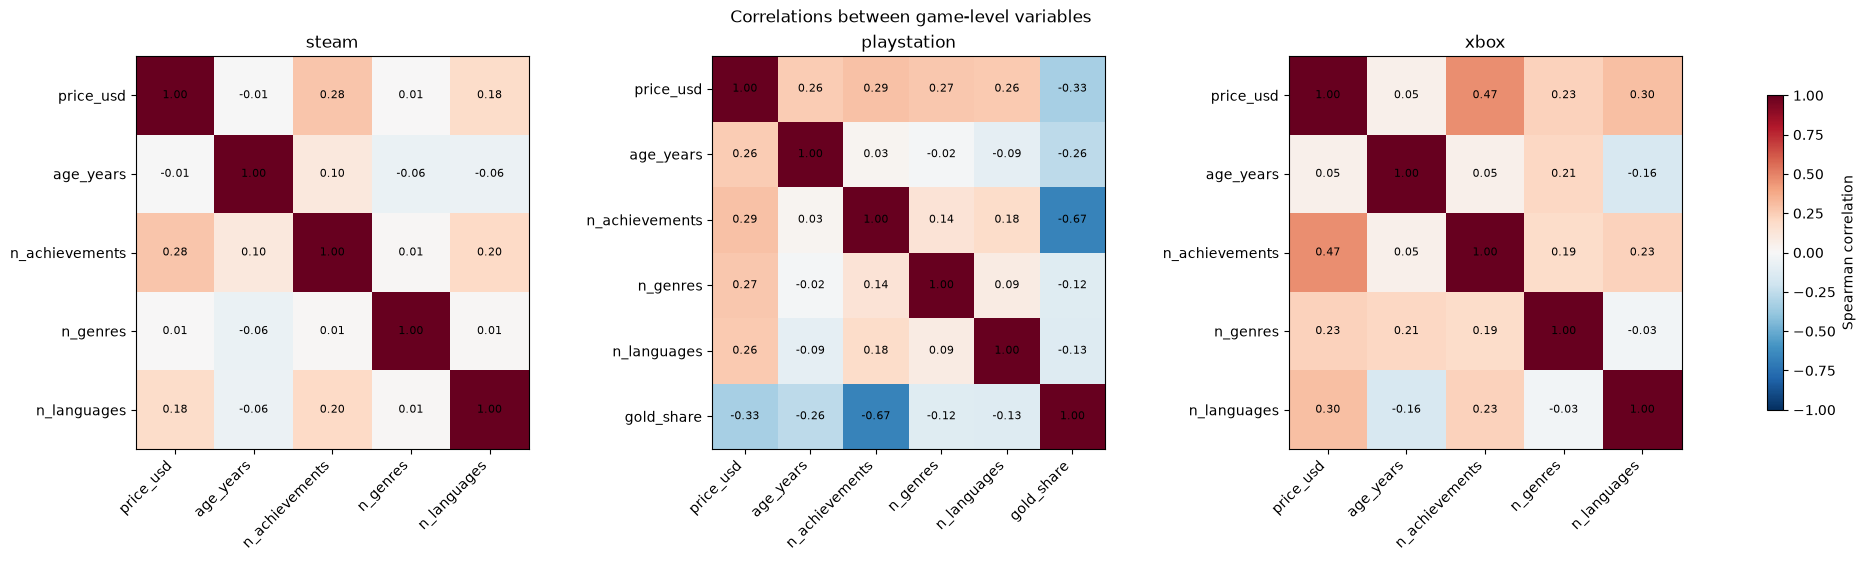

In [25]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
def game_level_features(platform):
    """One row per game: price on COMMON_DAY, age, number of achievements, genres and languages."""
    games = game[platform, "games"].set_index("gameid")
    prices = game[platform, "prices"]
    features = pd.DataFrame({
        "price_usd": prices[prices["date_acquired"] == COMMON_DAY].set_index("gameid")["usd"],
        "age_years": (COMMON_DAY - games["release_date"]).dt.days / 365.25,
        "n_achievements": game[platform, "achievements"].groupby("gameid").size(),
        "n_genres": parse_list_column(games["genres"]).str.len(),
        "n_languages": parse_list_column(games["supported_languages"]).str.len(),
    }).reindex(games.index)  # keep only games present in the games table
    if platform == "playstation":
        trophies = game[platform, "achievements"]
        features["gold_share"] = (trophies["rarity"] == "Gold").groupby(trophies["gameid"]).mean()
    return features

features = {platform: game_level_features(platform) for platform in PLATFORMS}

# Spearman correlation: rank-based, so robust to the strong skew of prices and achievement counts
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), layout="constrained")
for ax, platform in zip(axes, PLATFORMS):
    corr = features[platform].corr(method="spearman")
    image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.columns)
    for (i, j), value in np.ndenumerate(corr.values):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(platform)
fig.colorbar(image, ax=axes, shrink=0.8, label="Spearman correlation")
fig.suptitle("Correlations between game-level variables")
fig.savefig(FIG_DIR / "explore_game_correlations.png", dpi=150)
plt.show()

In [26]:
# Grouped statistics: median price by game age, and by PlayStation console
age_bins, age_labels = [0, 1, 3, 5, 10, 100], ["< 1", "1-3", "3-5", "5-10", "> 10"]
by_age = pd.concat({
    platform: features[platform].groupby(pd.cut(features[platform]["age_years"], age_bins, labels=age_labels),
                                         observed=True)["price_usd"].median()
    for platform in PLATFORMS
}, axis=1)
display(by_age.rename_axis("age (years)").round(2))

ps = features["playstation"].join(game["playstation", "games"].set_index("gameid")["platform"])
ps.groupby("platform", observed=True).agg(games=("price_usd", "size"), median_price=("price_usd", "median"),
                                          median_trophies=("n_achievements", "median"), median_gold_share=("gold_share", "median"))

,steam,playstation,xbox
age (years),,,
< 1,5.50,4.99,11.99
1-3,4.99,6.99,14.99
3-5,4.99,8.99,14.99
5-10,4.99,12.99,14.99
> 10,9.99,12.99,14.99


,games,median_price,median_trophies,median_gold_share
platform,,,,
PS Vita,995,9.99,21.0,0.147059
PS3,1571,14.99,35.0,0.076923
PS4,14163,7.99,21.0,0.230769
PS5,6422,6.99,22.0,0.307692


#### Game side: observations

Spearman correlations are computed per platform on one row per game (price on 22 February 2025).

- **Price rises with the number of achievements** on every platform (Spearman 0.28 on Steam, 0.29 on PlayStation, 0.47
  on Xbox): larger games define more achievements and cost more.
- **Age and price relate differently across platforms.** On Steam the median price stays near USD 5 for games up to ten
  years old (USD 9.99 beyond), and age and price are uncorrelated overall (-0.01). On PlayStation recent games are cheaper (median USD 4.99 for games under one year,
  USD 12.99 for games older than five years; Spearman 0.26).
- **Surprising PlayStation pattern:** the share of Gold trophies falls sharply as the number of trophies grows (Spearman
  -0.67) and is lower for more expensive games (-0.33). PS5 games are the cheapest (median USD 6.99) and have the highest
  Gold share (31 %), PS3 games the most expensive (USD 14.99) with the lowest (8 %). Small, cheap games award many Gold
  trophies, so Gold does not necessarily mean "hard"; this is a pattern worth testing as a question.

reviews posted before the account was created: 384


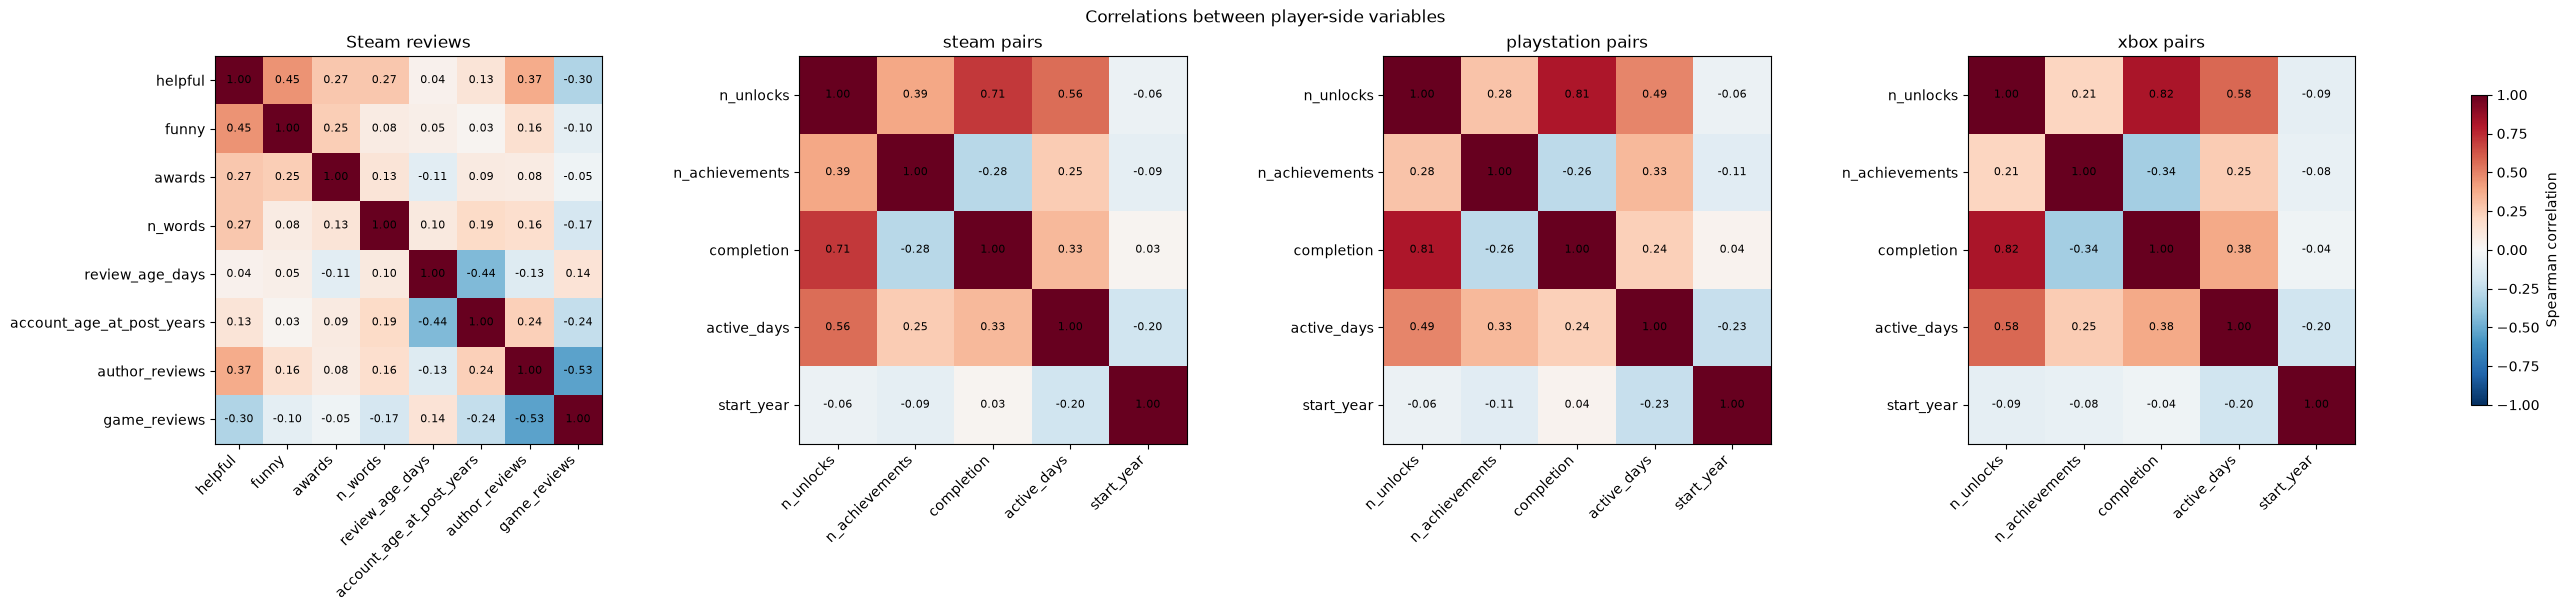

,reviews,helpful_>0_%
year posted,,
2010,733,10.4
2011,3203,11.8
2012,3883,16.8
2013,14050,35.1
2014,40207,40.3
2015,51170,37.5
2016,69458,38.7
2017,83406,41.6
2018,80324,41.1


,reviews,helpful_>0_%
words,,
1-3,391277,23.5
4-10,242152,25.8
11-30,227673,31.7
31-100,191577,44.1
> 100,149758,65.7


platform,median completion: steam,median completion: playstation,median completion: xbox
achievements in the game,,,
1-10,1.00,0.80,0.75
11-20,0.29,0.83,0.58
21-50,0.24,0.45,0.23
51-100,0.17,0.32,0.18
> 100,0.11,0.13,0.09


In [29]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
review_features = pd.read_parquet(PROCESSED_DIR / "steam_review_features.parquet")  # written in section 2.5
pairs = pd.read_parquet(PROCESSED_DIR / "history_player_game.parquet")              # written in section 2.3
account_created = load_player_table("steam", "players", usecols=["playerid", "created"], parse_dates=["created"]).set_index("playerid")["created"]

# Review level: what is known about the review, its author and its game, and what it received afterwards
rv = review_features.assign(
    review_age_days=(review_features["posted"].max() - review_features["posted"]).dt.days,
    account_age_at_post_years=(review_features["posted"] - review_features["playerid"].map(account_created)).dt.days / 365.25,
    author_reviews=review_features.groupby("playerid")["reviewid"].transform("size"),
    game_reviews=review_features.groupby("gameid")["reviewid"].transform("size"))
print("reviews posted before the account was created:", int((rv["account_age_at_post_years"] < 0).sum()))
review_cols = ["helpful", "funny", "awards", "n_words", "review_age_days", "account_age_at_post_years",
               "author_reviews", "game_reviews"]

# Pair level: one (player, game) pair, with the size of the game
pairs["active_days"] = (pairs["last_unlock"] - pairs["first_unlock"]).dt.days
pairs["start_year"] = pairs["first_unlock"].dt.year
pairs = pairs.join(pd.concat({p: game[p, "achievements"].groupby("gameid").size() for p in PLATFORMS},
                             names=["platform", "gameid"]).rename("n_achievements"), on=["platform", "gameid"])
pairs["completion"] = pairs["n_unlocks"] / pairs["n_achievements"]  # share of the game's achievements unlocked
pair_cols = ["n_unlocks", "n_achievements", "completion", "active_days", "start_year"]

# Spearman correlation: rank based, so robust to the heavy right tails of counts
panels = {"Steam reviews": rv[review_cols].astype("float64"),
          **{f"{p} pairs": pairs.loc[pairs["platform"] == p, pair_cols] for p in PLATFORMS}}
fig, axes = plt.subplots(1, 4, figsize=(26, 6), layout="constrained")
for ax, (title, data) in zip(axes, panels.items()):
    corr = data.corr(method="spearman")
    image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.columns)
    for (i, j), value in np.ndenumerate(corr.values):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
fig.colorbar(image, ax=axes, shrink=0.8, label="Spearman correlation")
fig.suptitle("Correlations between player-side variables")
fig.savefig(FIG_DIR / "explore_player_correlations.png", dpi=150)
plt.show()

# Grouped statistics. A review needs time to collect votes, so look at the share with votes by year and by length
has_votes = rv["helpful"] > 0
display(pd.DataFrame({"reviews": has_votes.groupby(rv["posted"].dt.year).size(),
                      "helpful_>0_%": (100 * has_votes.groupby(rv["posted"].dt.year).mean()).round(1)}).rename_axis("year posted"))
length_bin = pd.cut(rv["n_words"].astype("float64"), [0, 3, 10, 30, 100, 10_000], labels=["1-3", "4-10", "11-30", "31-100", "> 100"])
display(pd.DataFrame({"reviews": has_votes.groupby(length_bin, observed=True).size(),
                      "helpful_>0_%": (100 * has_votes.groupby(length_bin, observed=True).mean()).round(1)}).rename_axis("words"))

size_bin = pd.cut(pairs["n_achievements"], [0, 10, 20, 50, 100, 100_000], labels=["1-10", "11-20", "21-50", "51-100", "> 100"])
display(pairs.groupby(["platform", size_bin], observed=True)["completion"].median().unstack("platform")[PLATFORMS]
        .round(2).rename_axis("achievements in the game").add_prefix("median completion: "))

#### Player side: observations

Spearman correlations use one row per review (1,204,534) and one row per (player, game) pair.

- **Review length is the strongest signal of votes.** The share of reviews with at least two helpful votes rises from
  23.5 % (1 to 3 words) to 25.8 % (4 to 10), 31.7 % (11 to 30), 44.1 % (31 to 100) and 65.7 % (more than 100). Helpful
  votes also correlate with the author's number of reviews (0.37), funny votes (0.45), awards (0.27) and length (0.27),
  and negatively with the number of reviews of the game (-0.30).
- **Votes do not simply grow with age.** The share with votes is 10.4 % in 2010 and 16.8 % in 2012, 35 to 42 % from 2013 to
  2018, 29 to 34 % from 2019 to 2024 and 24.5 % in 2025 (1,552 reviews, few weeks to collect votes). Review age and
  helpful votes are almost uncorrelated (0.04), so a model needs a time-based split but no linear age effect. 384 reviews
  predate their author's account (probably edited, section 1.4).
- **Players finish a small share of large games.** Completion (share of the game's achievements unlocked) falls as games
  grow (Spearman -0.28 Steam, -0.26 PlayStation, -0.34 Xbox). The median is 1.00, 0.80 and 0.75 for games with at most 10
  achievements and only 0.11, 0.13 and 0.09 for games with more than 100; Steam games of 11 to 20 achievements already
  drop to 0.29.
- **Later pairs have less time to be observed.** Start year correlates negatively with the days between first and last
  unlock (-0.20 to -0.23) because the data end in December 2024, so "still active after N days" measures must handle this
  censoring (section 2.4). Unlocks follow active days (0.49 to 0.58).

## 3 Exploration summary

Game-side points come from sections 2.1 to 2.8 (`games`, `achievements`, `prices`); player-side points are added by
the owner of the player-side tables.

### 3.1 Key observations (3–5)

1. **The catalogues are dominated by recent, cheap games.** 68 % of Steam, 73 % of PlayStation and 53 % of Xbox games
   were released in 2020 or later, and the median price on 22 February 2025 is USD 4.99 on Steam, 7.99 on PlayStation
   and 14.99 on Xbox. Prices are strongly right-skewed (skewness 16.8 on Steam), so medians and log scales describe them
   better than means (sections 2.4, 2.5).
2. **Steam's seasonal sales are visible directly in the price data.** About 60 % (28 November to 4 December 2024) and
   62 % (20 December 2024 to 1 January 2025) of the games priced on every date sit below their own highest price,
   against 3 to 14 % on the other dates. Only the winter sale has a complete before, during and after period (section 2.4).
3. **PlayStation trophy grades do not simply reflect game size or price.** The share of Gold trophies falls as the
   number of trophies grows (Spearman -0.67) and as the price rises (-0.33); PS5 games are the cheapest (median USD 6.99)
   and award the most Gold trophies (31 % at the median). This is the most surprising game-side pattern (section 2.8).
4. **The behaviour data are a small, selected and partly artificial sample.** Only 4,838 Steam, 5,000 PlayStation and
   4,984 Xbox players (1.1 to 1.8 % of their tables) have any unlock, they come from achievement leaderboards, and on Steam
   55.3 % of the unlocks sit in groups of five or more in the same second (against 1.5 % and 1.3 % on the consoles), with
   one player holding 545,949 rows. This is the most surprising player-side finding: Steam clock times and unlock counts
   are only partly human behaviour (sections 2.2, 2.4).
5. **Review length is the strongest signal of votes.** 34.0 % of the Steam reviews have at least two helpful votes, and
   this share rises from 23.5 % for reviews of 1 to 3 words to 65.7 % for reviews of more than 100 words, while review age
   barely matters (Spearman 0.04) (sections 2.6, 2.8).

### 3.2 Serious data quality issues

- **Incomplete console game tables:** 7,570 PlayStation game ids (24.6 %) and 830 Xbox ids appear in `prices` and
  `achievements` but not in `games`, so 26 % of PlayStation trophies have no genre or release date (section 2.3).
- **Inconsistent genre labels:** each platform uses its own taxonomy, PlayStation and Xbox store the same label in
  different cases (*Puzzle* and *puzzle*), and some Steam labels are store tags rather than genres (*Indie*, *Early
  Access*, *Free To Play*) (section 2.6).
- **Placeholder and implausible prices:** 72 prices of exactly 0 (GBP and RUB) sit on rows with a positive USD price,
  and one PlayStation game costs USD 0.02 (section 2.5).
- **Uneven price snapshots:** the PlayStation snapshot of 25 February 2025 holds 1,374 rows instead of 30,721, and the
  consoles have only two complete price dates (section 2.4).
- **Test builds in the Steam catalogue:** 5,294 playtests have no metadata and never a price (sections 2.2, 2.7).
- **Bulk unlocks on Steam:** 55.3 % of the Steam unlocks come in groups of five or more in the same second, 190,799 are
  dated 28 September 2018 and one player has 545,949 unlocks, so timing and counts need a robustness check (section 2.4).
- **Very few players with behaviour data:** 1.1 to 1.8 % of the players have unlocks and they are achievement hunters,
  so behavioural findings do not describe the average player (sections 1.4, 2.2).
- **Missing game metadata for unlocks:** 21.6 % of the PlayStation and 8.3 % of the Xbox unlocks belong to games that
  have no row in `games` (no genre or release date); on Steam only 0.4 % do (section 2.3).
- **Steam profile gaps that come together:** 41.9 % of the players have no country, 11.2 % no creation date, 54.2 % of the
  libraries and 20.1 % of the friend lists are empty. The 47,669 accounts without a creation date almost always also have
  no friends and no library, so the gaps are not random (section 2.7).
- **Vote counts of `reviews` are distorted:** no review has exactly one helpful vote and counts above 999 are cut
  (section 1.4), 32.5 % of the reviews have three words or fewer, many are placeholders (a sun emoji 14,885 times,
  `(Review text hidden)` 3,898 times) and the awards of the most awarded reviews belong to a single author (sections
  2.2, 2.5).

### 3.3 Preprocessing plan

| Step | Tables | Rule | Output in `data/processed/` | Used by |
| --- | --- | --- | --- | --- |
| Load | `games`, `achievements`, `prices` | `load_game_table` with the settings of section 2.1 | – | every analysis |
| Remove test builds | Steam `games` | exclude titles containing "Playtest" from game-level analyses | – | game-level analyses |
| Normalise genres | `games` | parse the lists, merge case variants into the most frequent spelling, group labels used by fewer than 1 % of games as "Other", keep missing as "Unknown" | – | analyses by genre |
| Clean prices | `prices` | drop rows without a USD price (not for sale); treat a 0 in any currency as missing; compare platforms on 22 February 2025 | – | price analyses |
| Steam price panel | Steam `prices` | keep the 77,495 games with a USD price on all 45 dates; one row per game, one column per date | `steam_prices_wide.parquet` | analyses of Steam sales |
| Attach game attributes | `prices`, `achievements` -> `games` | left join on `gameid`; report how many rows get no attribute | – | analyses needing genre or release date |
| Load | player-side tables | `load_player_table` with the settings of section 2.1 (int64 ids on Steam, parsed dates, no `NaN` for the nickname `null`) | – | every analysis |
| Attribute unlocks to games | `history` -> `achievements` | map `achievementid` to `gameid` (all unlocks match); no inner join with `games` | – | behaviour analyses |
| Pair table | `history` | one row per (player, game): first unlock, last unlock, number of unlocks | `history_player_game.parquet` (2,281,898 rows) | behaviour analyses |
| Flag bulk unlocks | `history` | mark unlocks in groups of five or more in the same second for the same player; repeat the analysis without them | – | behaviour analyses (robustness) |
| Handle observation limits | pairs | keep a pair for an N-day measure only if it starts at least N days before the end of its platform's history | – | measures over time |
| Review features | `reviews` | word count, missing-text flag and ASCII flag; the text itself is dropped; `helpful > 0` means at least two votes | `steam_review_features.parquet` (1,204,534 rows) | review analyses |
| Handle Steam gaps | `players`, `purchased_games` | `country` "Unknown" and countries under 1 % as "Other"; missing creation date kept as missing (indicator in a model); library features only for the 46,941 non-empty libraries | – | analyses by country, account age or library |
| Drop identifying columns | PlayStation and Xbox `players` | drop `nickname` | – | every analysis |

### 3.4 Patterns that could lead to questions

- **Discount depth and price recovery around Steam sales** (section 2.4): how deep the discounts go, for which games, and
  whether prices return to, or rise above, their pre-sale level.
- **Trophy grades versus real difficulty on PlayStation** (section 2.8): the Gold share depends strongly on game size and
  price, so the grade may not mean "hard"; unlock rates from `history` can test this.
- **Platform-specific pricing** (sections 2.5, 2.8): Xbox prices are higher and tied to the number of achievements
  (Spearman 0.47), while recent PlayStation games are cheaper than older ones.
- **Staying power after the first unlock** (sections 2.4, 2.8): completion falls as games get larger (median 1.00 for games
  with at most 10 achievements against about 0.1 for games with more than 100), 35 to 40 % of the pairs span a day or
  less, and later pairs are observed for a shorter time. Whether players come back, and how this differs by game size
  and platform, needs censoring and the bulk-unlock flag to be handled.
- **Which reviews receive helpful votes** (sections 2.6, 2.8): 34 % of the reviews have at least two votes, length and
  the author's number of reviews relate to votes, and the share of reviews with votes changes by period, so a model
  has to use features known at posting time and a time-based split.